In [1]:
import os
import pickle
from pathlib import Path
from IPython.display import display
import numpy as np


os.chdir(r"C:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience")

import pandas as pd
# Set global options to unlimited
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
# pd.set_option('display.max_columns', None)


### [Optional] Combine pkl

In [ ]:
import pickle
import pandas as pd

with open('results/prior/test_30_40dollar/data.pkl', 'rb') as f:
    data1 = pickle.load(f)

with open('results/prior/test_20dollar/data.pkl', 'rb') as f:
    data2 = pickle.load(f)

combined = {}
for model in data1.keys():
    combined[model] = pd.concat([data1[model], data2[model]], ignore_index=True)

with open('results/prior/boundary.pkl', 'wb') as f:
    pickle.dump(combined, f)

### [Prior check] Check upper boundary of LLMs.

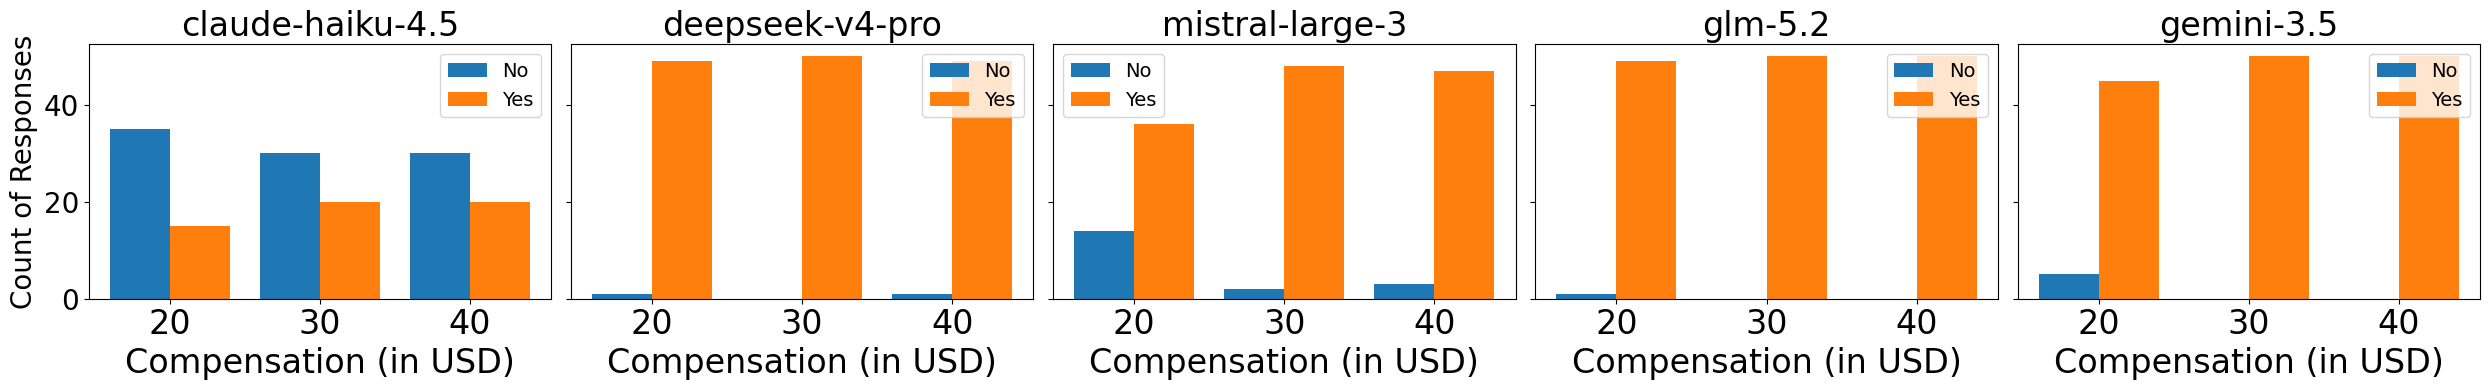

In [54]:
import pickle
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

path_results = Path("results/prior/boundary.pkl")
with open(path_results, "rb") as f:
    data = pickle.load(f)

reward_values = [20, 30, 40]
models = list(data.keys())

fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), sharey=True)
if len(models) == 1:
    axes = [axes]

for ax, model in zip(axes, models):
    df = data[model]
    counts = {rv: df[df['reward_value'] == rv]['output'].value_counts() for rv in reward_values}

    outputs = sorted(set().union(*[c.index for c in counts.values()]))  # e.g. ['No', 'Yes']
    x = np.arange(len(reward_values))
    width = 0.8 / len(outputs)

    for i, out in enumerate(outputs):
        heights = [counts[rv].get(out, 0) for rv in reward_values]
        ax.bar(x + i * width, heights, width, label=out)

    ax.set_title(model,fontsize=24)
    ax.set_xticks(x + width * (len(outputs) - 1) / 2)
    ax.set_xticklabels(reward_values,fontsize=24)
    ax.set_xlabel("Compensation (in USD)",fontsize=24)
    ax.tick_params(axis='y', labelsize=20) 
    ax.legend(fontsize=14)


axes[0].set_ylabel("Count of Responses",fontsize=20)
plt.tight_layout()
plt.show()

## LLM output: yes or no

### Plot yes perncetage distribution by model x country

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import pickle
import os
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error
os.chdir(r"C:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience")


path_results1 = Path("results/country_2/193countries_25dollar/data.pkl")
with open(path_results1, "rb") as f:
    df1 = pickle.load(f)

# path_results2 = Path("results_global/country/test_25dollar_fit50/data.pkl")
# with open(path_results2, "rb") as f:
#     df2 = pickle.load(f)

# models=['claude-haiku-4.5', 'mistral-large-3', 'gpt-5.4-mini', 'glm-5.2', 'deepseek-v4-pro']
# country_name=["Afghanistan","Switzerland"]

models= ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]
country_name=["China"]

for i in models:
    # print(f"Processing model: {i}")
    df1_model=df1[i]
    # df2_model=df2[i]

    for c in country_name:
        # print(f"Processing country: {c}")

        # Define a helper function to process the data
        def process_data(df, country_name=c): # Afghanistan
            # Filter by country
            df_filtered = df[df['country'] == country_name].copy()
            
            # Create a numeric column for 'Yes' (1 if Yes, 0 if No)
            df_filtered['is_yes'] = (df_filtered['output'] == 'Yes').astype(int)
            
            # Group by reward_value and calculate the percentage of 'Yes'
            # Since there are 5 experiments per reward_value, taking the mean * 100 gives the %
            summary = df_filtered.groupby('reward_value')['is_yes'].mean() * 100
            
            return summary

        # Process both datasets
        summary1 = process_data(df1_model)
        # summary2 = process_data(df2_model)

        # --- Isotonic Regression and Metrics Calculation ---
        reward_values = np.array(summary1.index)
        yes_percentages = np.array(summary1.values)
        iso_reg = IsotonicRegression(increasing=True) 
        y_isotonic = iso_reg.fit_transform(reward_values, yes_percentages)
        mae = mean_absolute_error(yes_percentages, y_isotonic)
        # r2 = r2_score(yes_percentages, y_isotonic)

        # Combined Comparison ---
        plt.figure(figsize=(10, 6))
        plt.plot(summary1.index, summary1.values, marker='o', linestyle='-', color='blue',label=f'MAE: {mae:.2f}') # label=f'MAE: {mae:.2f}'
        # plt.plot(summary2.index, summary2.values, marker='s', linestyle='-', color='red', label='data_log')
        plt.title(f'LLMs\' Response for Compensation ({c} x {i})', font=dict(size=22), y=1.06) # pad=20
        plt.xlabel('Reward (USD)', font=dict(size=18))
        plt.ylabel('Percent of "Yes" (out of 5 repetitions)', font=dict(size=18))
        plt.xticks(fontsize=18)
        plt.yticks(fontsize=18)
        # plt.yaxis=dict(range=[0, 100])
        plt.ylim(-5, 105)
        plt.legend(fontsize=14) #loc='upper left', bbox_to_anchor=(0.02, 0.98),
        plt.grid(True, alpha=0.3)
        plt.show()

### Plot yes percentage distribution by model x country (MULTIPLE)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import pickle

# Create directory if it doesn't exist
# After os.chdir(...)
PLOT_DIR = Path.cwd() / "figures" / "distribution"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print(PLOT_DIR)  # Check where plots will be saved


import os
os.chdir(r"C:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience")


path_results1 = Path("results/country_1/rt1/data.pkl")
with open(path_results1, "rb") as f:
    df1 = pickle.load(f)

path_results2 = Path("results/country_1/rt1/data.pkl")
with open(path_results2, "rb") as f:
    df2 = pickle.load(f)


# path_results3 = Path("results_global/country/test_25dollar_fit101/data.pkl")
# with open(path_results3, "rb") as f:
#     df3 = pickle.load(f)

# ['claude-haiku-4.5', 'mistral-large-3', 'gpt-5.4-mini', 'glm-5.2', 'deepseek-v4-pro']
models=['gemini-3.5','gemini-3']
country_name=["Afghanistan","Switzerland"]

for i in models:
    print(f"Processing model: {i}")
    df1_model=df1[i]
    df2_model=df2[i]
    # df3_model=df3[i]

    for c in country_name:
        print(f"Processing country: {c}")

# Define a helper function to process the data
        def process_data(df, country_name=c): # Afghanistan
            # Filter by country
            df_filtered = df[df['country'] == country_name].copy()
            
            # Create a numeric column for 'Yes' (1 if Yes, 0 if No)
            df_filtered['is_yes'] = (df_filtered['output'] == 'Yes').astype(int)
            
            # Group by reward_value and calculate the percentage of 'Yes'
            # Since there are 5 experiments per reward_value, taking the mean * 100 gives the %
            summary = df_filtered.groupby('reward_value')['is_yes'].mean() * 100
            
            return summary

        # Process both datasets
        summary1 = process_data(df1_model)
        summary2 = process_data(df2_model)
        # summary3 = process_data(df3_model)

    # Combined Comparison ---
        plt.figure(figsize=(10, 6))
        plt.plot(summary1.index, summary1.values, marker='o', linestyle='-', color='blue', label='21steps')
        plt.plot(summary2.index, summary2.values, marker='s', linestyle='-', color='red', label='50 steps')
        # plt.plot(summary3.index, summary3.values, marker='^', linestyle='-', color='green', label='101 steps')
        plt.title(f'Comparison: "Yes" Percentage ({c} x {i}) for 21 vs 50 vs 101 steps (even spaced)')
        plt.xlabel('Reward Money (reward_value)')
        plt.ylabel('% of "Yes" (out of 5)')
        plt.legend()
        plt.grid(True, which='major',alpha=0.3)

        # Save the figure
        # filename = f"{i}_{c}(even spaced).png".replace(" ", "_")
        # plt.savefig(PLOT_DIR / filename, dpi=300, bbox_inches="tight")

        plt.show()
        plt.close()


### Check the LLMs output: yes or no.

#### Remove those problematic results from a specific model (e.g., with too many none)

In [ ]:

import pickle

# Load
with open('results/country_3/193countries_25dollar/data.pkl', 'rb') as f:
    data = pickle.load(f)

print('Before:', list(data.keys()))

# Remove the model
del data['mistral-large-3']

print('After:', list(data.keys()))

# Save
with open('results/country_2/193countries_25dollar/data.pkl', 'wb') as f:
    pickle.dump(data, f)

Before: ['claude-haiku-4.5', 'gpt-5.4-mini', 'glm-5.2', 'deepseek-v4-pro', 'mistral-large-3']
After: ['claude-haiku-4.5', 'gpt-5.4-mini', 'glm-5.2', 'deepseek-v4-pro']


#### Remove partial problematic results from a specific model and a country (e.g., with too many none)

In [28]:
import pickle
import shutil

path = 'results/country_3/193countries_25dollar/data.pkl'
model_name = 'glm-5.2'
country_to_remove = 'Colombia'
experiment_to_remove = 2

# Backup first, since this overwrites the original file
shutil.copy(path, path + '.bak')

# Load
with open(path, 'rb') as f:
    data = pickle.load(f)

df = data[model_name]

# Rows to delete: country is Colombia AND experiment is 2
mask = (df['country'].str.strip() == country_to_remove) & (df['experiment'] == experiment_to_remove)

print(f'Before: {len(df)} rows, {mask.sum()} will be removed')

# Keep everything that does NOT match both conditions
data[model_name] = df[~mask].reset_index(drop=True)

print(f'After:  {len(data[model_name])} rows')
print('Models:', list(data.keys()))

# Save
with open(path, 'wb') as f:
    pickle.dump(data, f)

Before: 11550 rows, 50 will be removed
After:  11500 rows
Models: ['claude-haiku-4.5', 'gpt-5.4-mini', 'glm-5.2']


In [10]:

path_results = Path("results/base_2/rt2/data.pkl")
# results_global/country/test_10countries/data_log.pkl

with open(path_results, "rb") as f:
    data = pickle.load(f)

print (data)
# for i in data.keys():
#     print( f"Model: {i}" )
#     data_model=data[i]
#     data_sorted=data[i].sort_values(by=["country","reward_value"], ascending=[True,True]) 
#     print(data_sorted)

# check for each model, how many unique outputs from it.
# for i in data.keys():
#     print( f"Model: {i}" )
#     data_model=data[i]
#     # data_model=data_model[data_model['reward_value']==40]
#     val_counts = data_model['output'].value_counts(dropna=False)
#     print(f"Unique values: {val_counts.index.to_numpy()}")
#     print(f"Counts: {val_counts.to_numpy()}")
#     print("-" * 30)
    # data_model=data[i].sort_values(by=["country","reward_value"], ascending=[True,True]) 
    # print(data_model)

{'claude-haiku-4.5':      reward_value  quantity  experiment output
0        1.000000      60.0           1     No
1        1.489796      60.0           1     No
2        1.979592      60.0           1     No
3        2.469388      60.0           1     No
4        2.959184      60.0           1     No
5        3.448980      60.0           1     No
6        3.938776      60.0           1    Yes
7        4.428571      60.0           1     No
8        4.918367      60.0           1     No
9        5.408163      60.0           1    Yes
10       5.897959      60.0           1    Yes
11       6.387755      60.0           1    Yes
12       6.877551      60.0           1    Yes
13       7.367347      60.0           1    Yes
14       7.857143      60.0           1    Yes
15       8.346939      60.0           1    Yes
16       8.836735      60.0           1    Yes
17       9.326531      60.0           1    Yes
18       9.816327      60.0           1    Yes
19      10.306122      60.0           1

### Check the details of output: per country/model

In [13]:
path_results = Path("results/base_2/rt2/data.pkl")
# results_global/country/test_10countries/data_log.pkl

with open(path_results, "rb") as f:
    data = pickle.load(f)

print (data)

# models=['claude-haiku-4.5', 'mistral-large-3', 'gpt-5.4-mini', 'glm-5.2', 'deepseek-v4-pro']
# data_model=data['glm-5.2'] # llama3_3_70b, deepseek-v4-pro 
# data_model=data_model.sort_values(by=["country","reward_value"], ascending=[True,True]) 
# print(data_model)
# # display(data_model)


#For each country
# data_country = data_model.loc[data_model["country"] == "Switzerland"]
# print (data_country)
# display(data_country)


{'claude-haiku-4.5':      reward_value  quantity  experiment output
0        1.000000      60.0           1     No
1        1.489796      60.0           1     No
2        1.979592      60.0           1     No
3        2.469388      60.0           1     No
4        2.959184      60.0           1     No
5        3.448980      60.0           1     No
6        3.938776      60.0           1    Yes
7        4.428571      60.0           1     No
8        4.918367      60.0           1     No
9        5.408163      60.0           1    Yes
10       5.897959      60.0           1    Yes
11       6.387755      60.0           1    Yes
12       6.877551      60.0           1    Yes
13       7.367347      60.0           1    Yes
14       7.857143      60.0           1    Yes
15       8.346939      60.0           1    Yes
16       8.836735      60.0           1    Yes
17       9.326531      60.0           1    Yes
18       9.816327      60.0           1    Yes
19      10.306122      60.0           1

## LLM output: transition

### Check transition values per country/model and the overall mean

In [41]:
path_results = Path("results/country_3/rt3/LR_results.pkl")
# results_global/country/test_10countries/data_log.pkl

with open(path_results, "rb") as f:
    data = pickle.load(f)

# print (data)

# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()

    if x.startswith("<"):
        return 1.0

    if x.startswith(">"):
        return 25.0

    return float(x)


model_name = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]
for model in model_name:
    print(f"Model: {model}")
    df_llm = data[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)
    overall_mean = df_llm["transition"].mean().round(1)
    print(f"Overall mean: {overall_mean}")


Model: claude-haiku-4.5
Overall mean: 24.9
Model: deepseek-v4-pro
Overall mean: 5.0
Model: glm-5.2
Overall mean: 3.4
Model: gpt-5.4-mini
Overall mean: 12.9
Model: mistral-large-3
Overall mean: 25.0


In [45]:
path_results = Path("results/country_1/rt1/LR_results.pkl")
# results_global/country/test_10countries/data_log.pkl

with open(path_results, "rb") as f:
    data = pickle.load(f)

# print (data)

# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()

    if x.startswith("<"):
        return 1.0

    if x.startswith(">"):
        return 25.0

    return float(x)


model_name = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]
for model in model_name:
    print(f"Model: {model}")
    df_llm = data[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)
    overall_mean = df_llm["transition"].mean().round(1)
    print(df_llm)
    # print(f"Overall mean: {overall_mean}")



Model: claude-haiku-4.5
                              country  quantity  transition
0                         Afghanistan      60.0   24.565791
1                             Albania      60.0   23.124436
2                             Algeria      60.0   25.000000
3                             Andorra      60.0   25.000000
4                              Angola      60.0   12.701667
5                 Antigua and Barbuda      60.0   12.012092
6                           Argentina      60.0   25.000000
7                             Armenia      60.0   15.496926
8                           Australia      60.0   25.000000
9                             Austria      60.0   25.000000
10                         Azerbaijan      60.0   15.593622
11                            Bahamas      60.0   14.181276
12                            Bahrain      60.0   10.154865
13                         Bangladesh      60.0    5.632597
14                           Barbados      60.0   20.669567
15              

#### transition values per continent

In [8]:
import country_converter as coco 

path_results = Path("results/country_1/rt1/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)

# print(results)
# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()

    if x.startswith("<"):
        return 1.0

    if x.startswith(">"):
        return 25.0

    return float(x)


model_name = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]
for model in model_name:
    print(f"Model: {model}")
    df_llm = results[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)
    df_llm["continent"] = coco.convert(names=df_llm["country"], to="continent_7")
    df_summary = df_llm.groupby("continent", as_index=False)["transition"].mean().round(1)
    df_summary = df_summary.rename(columns={"transition": "continent_mean"})
    print(df_summary)


Model: claude-haiku-4.5
       continent  continent_mean
0         Africa             8.1
1           Asia            14.8
2         Europe            24.3
3  North America            13.8
4        Oceania            12.8
5  South America            16.6
Model: deepseek-v4-pro
       continent  continent_mean
0         Africa             1.7
1           Asia             3.1
2         Europe             5.5
3  North America             3.3
4        Oceania             3.5
5  South America             2.6
Model: glm-5.2
       continent  continent_mean
0         Africa             1.1
1           Asia             2.8
2         Europe             5.8
3  North America             3.3
4        Oceania             2.9
5  South America             1.8
Model: gpt-5.4-mini
       continent  continent_mean
0         Africa             1.0
1           Asia             1.0
2         Europe             1.8
3  North America             1.1
4        Oceania             1.2
5  South America           

### Quick check all three robustness experiment distribution

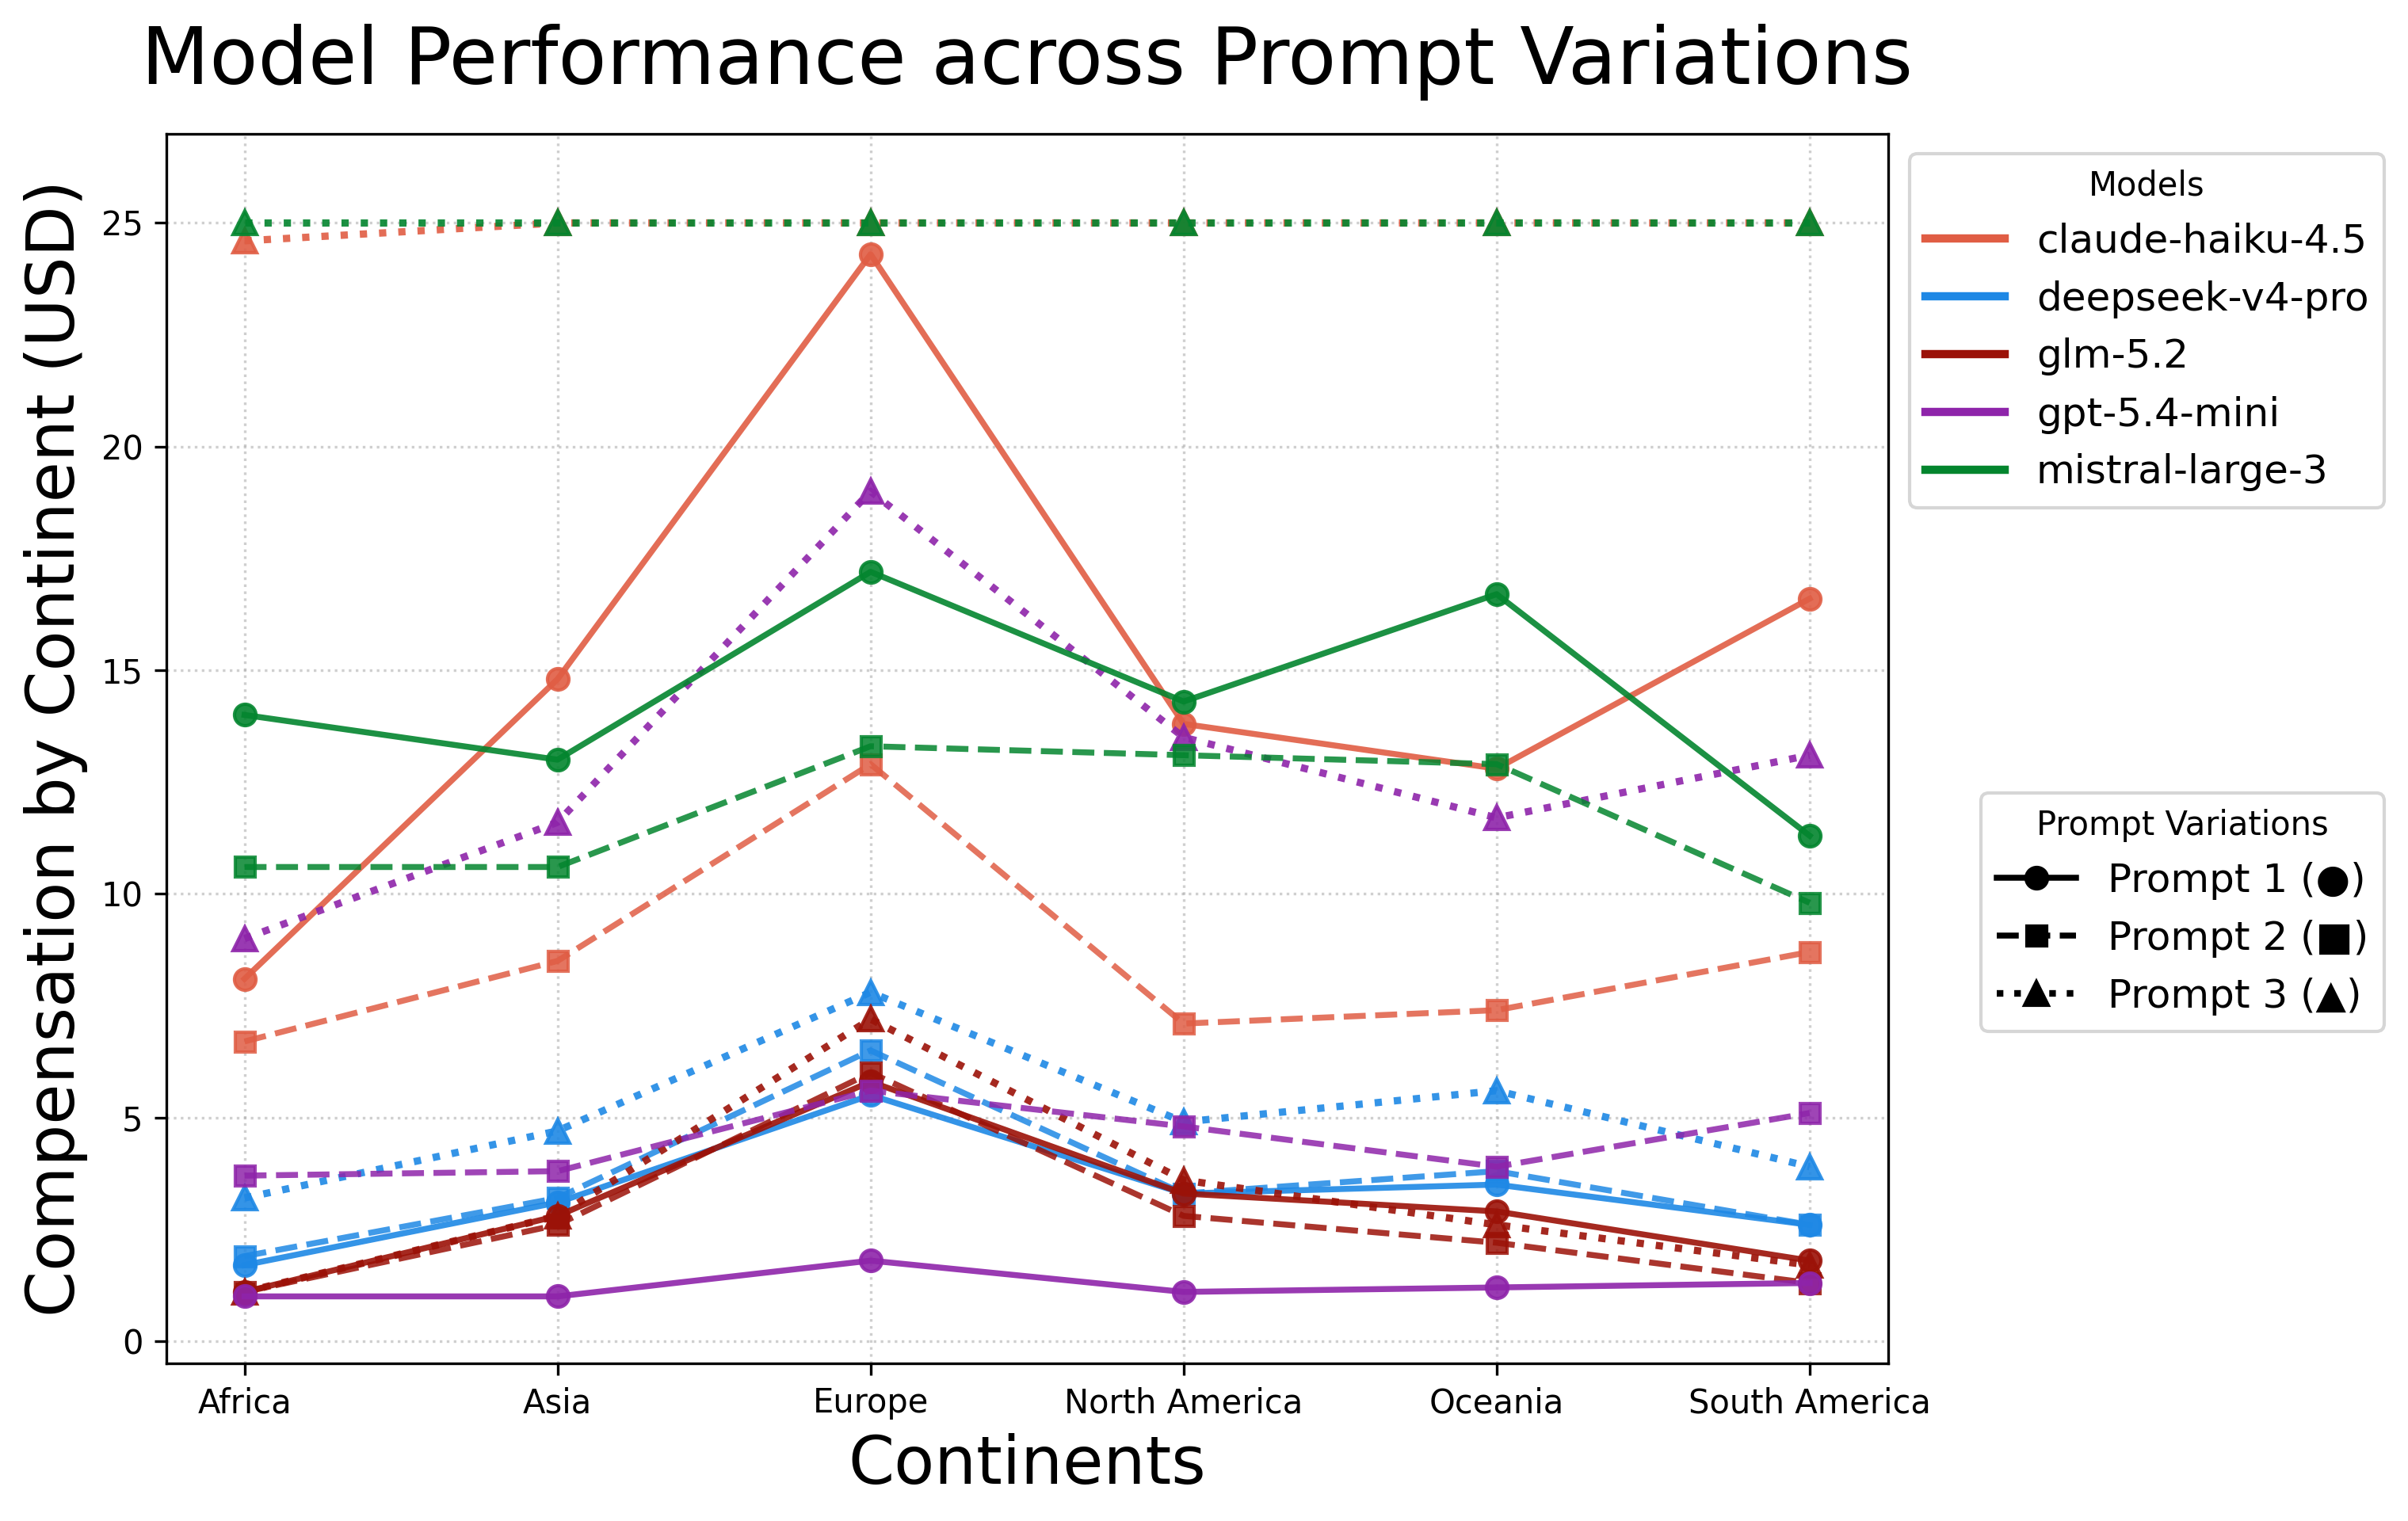

In [68]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 1. Continent & Model Setup
continents = ["Africa", "Asia", "Europe", "North America", "Oceania", "South America"]
models = ["claude-haiku-4.5", "deepseek-v4-pro", "glm-5.2", "gpt-5.4-mini", "mistral-large-3"]

data_exp1 = {
    "claude-haiku-4.5": [8.1, 14.8, 24.3, 13.8, 12.8, 16.6],
    "deepseek-v4-pro":  [1.7,  3.1,  5.5,  3.3,  3.5,  2.6],
    "glm-5.2":          [1.1,  2.8,  5.8,  3.3,  2.9,  1.8],
    "gpt-5.4-mini":     [1.0,  1.0,  1.8,  1.1,  1.2,  1.3],
    "mistral-large-3":  [14.0, 13.0, 17.2, 14.3, 16.7, 11.3],
}

data_exp2 = {
    "claude-haiku-4.5": [6.7,  8.5, 12.9,  7.1,  7.4,  8.7],
    "deepseek-v4-pro":  [1.9,  3.2,  6.5,  3.3,  3.8,  2.6],
    "glm-5.2":          [1.1,  2.6,  6.0,  2.8,  2.2,  1.3],
    "gpt-5.4-mini":     [3.7,  3.8,  5.6,  4.8,  3.9,  5.1],
    "mistral-large-3":  [10.6, 10.6, 13.3, 13.1, 12.9,  9.8],
}

data_exp3 = {
    "claude-haiku-4.5": [24.6, 25.0, 25.0, 25.0, 25.0, 25.0],
    "deepseek-v4-pro":  [3.2,  4.7,  7.8,  4.9,  5.6,  3.9],
    "glm-5.2":          [1.1,  2.8,  7.2,  3.6,  2.6,  1.7],
    "gpt-5.4-mini":     [9.0, 11.6, 19.0, 13.5, 11.7, 13.1],
    "mistral-large-3":  [25.0, 25.0, 25.0, 25.0, 25.0, 25.0],
}

colors = {
    "claude-haiku-4.5": "#E05D44",
    "deepseek-v4-pro":  "#1E88E5",
    "glm-5.2":          "#9B1208",
    "gpt-5.4-mini":     "#8E24AA",
    "mistral-large-3":  "#03852E"
}

# 2. Plotting
fig, ax = plt.subplots(figsize=(10.5, 6.5), dpi=300)

for model in models:
    color = colors[model]
    # Round 1
    ax.plot(continents, data_exp1[model], color=color, linestyle='-',
            marker='o', markersize=6.5, linewidth=1.8, alpha=0.9)
    # Round 2
    ax.plot(continents, data_exp2[model], color=color, linestyle='--',
            marker='s', markersize=6.0, linewidth=1.8, alpha=0.85)
    # Round 3
    ax.plot(continents, data_exp3[model], color=color, linestyle=':',
            marker='^', markersize=7.0, linewidth=2.2, alpha=0.9)

ax.set_title("Model Performance across Prompt Variations", fontsize=24, pad=15)
ax.set_xlabel("Continents", fontsize=20,)
ax.set_ylabel("Compensation by Continent (USD)", fontsize=20)
ax.set_ylim(-0.5, 27)
ax.grid(True, linestyle=":", alpha=0.6)

# 3. Two-Panel Legend
model_handles = [Line2D([0], [0], color=colors[m], lw=2.5, label=m) for m in models]
exp_handles = [
    Line2D([0], [0], color="black", linestyle="-", marker="o", markersize=6.5, lw=1.8, label="Prompt 1 (●)"),
    Line2D([0], [0], color="black", linestyle="--", marker="s", markersize=6.0, lw=1.8, label="Prompt 2 (■)"),
    Line2D([0], [0], color="black", linestyle=":", marker="^", markersize=7.0, lw=2.0, label="Prompt 3 (▲)")
]

leg1 = ax.legend(handles=model_handles, title="Models", loc="upper right", bbox_to_anchor=(1.30, 1.0), frameon=True,fontsize=12)
leg2 = ax.legend(handles=exp_handles, title="Prompt Variations", loc="upper right", bbox_to_anchor=(1.30, 0.48), frameon=True,fontsize=12)
ax.add_artist(leg1)

plt.tight_layout()
plt.show()

The mean across all three prompt varations 

In [ ]:
import numpy as np
import pandas as pd

# 1. Continent & Model Setup
continents = ["Africa", "Asia", "Europe", "North America", "Oceania", "South America"]
models = ["claude-haiku-4.5", "deepseek-v4-pro", "glm-5.2", "gpt-5.4-mini", "mistral-large-3"]

data_exp1 = {
    "claude-haiku-4.5": [8.1, 14.8, 24.3, 13.8, 12.8, 16.6],
    "deepseek-v4-pro":  [1.7,  3.1,  5.5,  3.3,  3.5,  2.6],
    "glm-5.2":          [1.1,  2.8,  5.8,  3.3,  2.9,  1.8],
    "gpt-5.4-mini":     [1.0,  1.0,  1.8,  1.1,  1.2,  1.3],
    "mistral-large-3":  [14.0, 13.0, 17.2, 14.3, 16.7, 11.3],
}

data_exp2 = {
    "claude-haiku-4.5": [6.7,  8.5, 12.9,  7.1,  7.4,  8.7],
    "deepseek-v4-pro":  [1.9,  3.2,  6.5,  3.3,  3.8,  2.6],
    "glm-5.2":          [1.1,  2.6,  6.0,  2.8,  2.2,  1.3],
    "gpt-5.4-mini":     [3.7,  3.8,  5.6,  4.8,  3.9,  5.1],
    "mistral-large-3":  [10.6, 10.6, 13.3, 13.1, 12.9,  9.8],
}

data_exp3 = {
    "claude-haiku-4.5": [24.6, 25.0, 25.0, 25.0, 25.0, 25.0],
    "deepseek-v4-pro":  [3.2,  4.7,  7.8,  4.9,  5.6,  3.9],
    "glm-5.2":          [1.1,  2.8,  7.2,  3.6,  2.6,  1.7],
    "gpt-5.4-mini":     [9.0, 11.6, 19.0, 13.5, 11.7, 13.1],
    "mistral-large-3":  [25.0, 25.0, 25.0, 25.0, 25.0, 25.0],
}


# Region order used in your data lists
regions_data = ["Africa", "Asia", "Europe", "North America", "Oceania", "South America"]
# Column order used in the table in your picture
regions_table = ["Africa", "Asia", "Europe", "North America", "Oceania", "South America"]

# data_exp1, data_exp2, data_exp3 as defined in your message
experiments = [data_exp1, data_exp2, data_exp3]

# shape: (3 experiments, 5 models, 6 regions)
dfs = [pd.DataFrame(d, index=regions_data).T for d in experiments]
stack = np.stack([df.values for df in dfs])
models = dfs[0].index

mean = pd.DataFrame(stack.mean(axis=0), index=models, columns=regions_data)
std = pd.DataFrame(stack.std(axis=0, ddof=0), index=models, columns=regions_data)  # we hereby use the normal std (n=3)

# Reorder columns to match the picture
mean, std = mean[regions_table], std[regions_table]

# "mean ± std" table
final = mean.round(1).astype(str) + " ± " + std.round(1).astype(str)
final.index.name = "LLMs"
print(final.to_string())


# Optional: LaTeX output for the paper
print(final.to_latex())

                       Africa        Asia      Europe North America     Oceania South America
LLMs                                                                                         
claude-haiku-4.5  13.1 ± 10.0  16.1 ± 8.3  20.7 ± 6.8    15.3 ± 9.0  15.1 ± 9.0    16.8 ± 8.2
deepseek-v4-pro     2.3 ± 0.8   3.7 ± 0.9   6.6 ± 1.2     3.8 ± 0.9   4.3 ± 1.1     3.0 ± 0.8
glm-5.2             1.1 ± 0.0   2.7 ± 0.1   6.3 ± 0.8     3.2 ± 0.4   2.6 ± 0.4     1.6 ± 0.3
gpt-5.4-mini        4.6 ± 4.1   5.5 ± 5.5   8.8 ± 9.0     6.5 ± 6.4   5.6 ± 5.5     6.5 ± 6.0
mistral-large-3    16.5 ± 7.5  16.2 ± 7.7  18.5 ± 6.0    17.5 ± 6.6  18.2 ± 6.2    15.4 ± 8.4
\begin{tabular}{lllllll}
\toprule
 & Africa & Asia & Europe & North America & Oceania & South America \\
LLMs &  &  &  &  &  &  \\
\midrule
claude-haiku-4.5 & 13.1 ± 10.0 & 16.1 ± 8.3 & 20.7 ± 6.8 & 15.3 ± 9.0 & 15.1 ± 9.0 & 16.8 ± 8.2 \\
deepseek-v4-pro & 2.3 ± 0.8 & 3.7 ± 0.9 & 6.6 ± 1.2 & 3.8 ± 0.9 & 4.3 ± 1.1 & 3.0 ± 0.8 \\
glm-5.2 & 1.

## World maps

In [12]:
import pandas as pd
import plotly.express as px
import pickle
from pathlib import Path
import matplotlib.pyplot as plt

PLOT_DIR=Path("figures/world_map/Prompt_3")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

path_results = Path("results/country_3/rt3/LR_results.pkl")
with open(path_results, "rb") as f:
    data = pickle.load(f)

# 2. Define the adapted plotting function
def plot_transition_values(df: pd.DataFrame,
                           title: str,
                           out_html: str | None = None):
    """
    Takes a DataFrame with 'country' and 'transition' columns.
    - Cleans string values like '>25.0' into numeric floats.
    - Uses country *names* directly (Plotly locationmode='country names').
    - Saves an interactive HTML file if out_html is provided.
    """
    # Create a copy to avoid modifying the original dataframe
    plot_df = df.copy()
    
    # Clean the 'transition' column: convert >25 and <1 to numeric
    plot_df["transition_num"] = plot_df["transition"].astype(str).str.replace(r"[<>]", "", regex=True).astype(float)
    
    # Create the choropleth map
    fig = px.choropleth(
        plot_df,
        locations="country",
        locationmode="country names",  # Maps names like "Afghanistan" or "Belgium"
        color="transition_num",
        color_continuous_scale="YlGnBu", #YlGnBu
        range_color=(1, 25),           # Fixed range from 0 to 25 based on your limits
        title=title,
        labels={"transition_num": "Reward Money<br>(Dollar)"}, # Updated Legend title
        projection="natural earth",
    )
    
    # Adjust layout to match your previous look
    fig.update_layout(title_font=dict(size=20),
                    #   title_y=0.95,
                      margin=dict(l=0, r=0, t=40, b=0),
                    #   width=1000,   # <-- ADD THIS: Forces a wider bounding box
                    #   height=500,
                      coloraxis_colorbar=dict(title_font=dict(size=20),  tickfont=dict(size=20)))  #, thickness=15,len=0.6
    
    if out_html:
        fig.write_html(out_html, include_plotlyjs="cdn")
        
    return fig

# 3. Extract the data for a specific model and plot it
# ['claude-haiku-4.5', 'mistral-large-3', 'gemini-3.5', 'glm-5.2', 'deepseek-v4-pro']
model_name = ['claude-haiku-4.5', 'mistral-large-3', 'gpt-5.4-mini', 'glm-5.2', 'deepseek-v4-pro']
for model in model_name:
    df_model = data[model]

    # Generate and show the figure
    fig = plot_transition_values(
        df=df_model, 
        title=f"Worldwide Reward (USD) for 60-minute delay ({model})", 
        out_html=str(PLOT_DIR / f"wm_{model}.html")
    )

    # Save the figure
    filename = f"wm_{model}.png".replace(" ", "_")
    fig.write_image(PLOT_DIR / filename, scale=2)  # scale=2 for higher resolution

    fig.show()

#### World map, give <1.0 and >25.0 special color

In [ ]:
import pandas as pd
import plotly.graph_objects as go
import pickle
from pathlib import Path

# 1. Load your data
path_results = Path("results/country_1/rt1/LR_results.pkl")
with open(path_results, "rb") as f:
    data = pickle.load(f)

# 2. Define the plotting function using graph_objects
def plot_transition_values(df: pd.DataFrame,
                           title: str = "Transition Values by Country",
                           out_html: str | None = None):
    
    plot_df = df.copy()
    
    # Clean the column: strip out symbols to create a purely numeric column for filtering
    plot_df["transition_num"] = (
        plot_df["transition"]
        .astype(str)
        .str.replace(r"[<>]", "", regex=True)
        .astype(float)
    )
    
    # Split data into our three color groups
    df_low = plot_df[plot_df["transition_num"] == 1.0]
    df_high = plot_df[plot_df["transition_num"] == 25.0]
    df_normal = plot_df[(plot_df["transition_num"] > 1.0) & (plot_df["transition_num"] < 25.0)]
    
    # Initialize a Plotly Graph Objects figure
    fig = go.Figure()
    
    # Layer 1: Normal values (1.0 to 25.0) -> Viridis color scale
    if not df_normal.empty:
        fig.add_trace(go.Choropleth(
            locations=df_normal['country'],
            locationmode="country names",
            z=df_normal['transition_num'],
            colorscale="Viridis",
            zmin=1.0,
            zmax=25.0,
            colorbar_title="Transition<br>Value",
            text=df_normal['transition'], # Shows original text on hover
            hovertemplate="<b>%{location}</b><br>Value: %{text}<extra></extra>"
        ))
        
    # Layer 2: Values < 1.0 -> Purple
    if not df_low.empty:
        fig.add_trace(go.Choropleth(
            locations=df_low['country'],
            locationmode="country names",
            z=[1] * len(df_low), # Dummy value just to trigger the color
            colorscale=[[0, "black"], [1, "black"]],
            showscale=False,     # Hides secondary colorbar
            text=df_low['transition'], 
            hovertemplate="<b>%{location}</b><br>Value: %{text}<extra></extra>"
        ))
        
    # Layer 3: Values > 25.0 -> Yellow
    if not df_high.empty:
        fig.add_trace(go.Choropleth(
            locations=df_high['country'],
            locationmode="country names",
            z=[1] * len(df_high), # Dummy value just to trigger the color
            colorscale=[[0, "yellow"], [1, "yellow"]],
            showscale=False,      # Hides secondary colorbar
            text=df_high['transition'],
            hovertemplate="<b>%{location}</b><br>Value: %{text}<extra></extra>"
        ))
        
    # Update styling to match your previous layout
    fig.update_layout(
        title=title,
        geo=dict(projection_type="natural earth"),
        margin=dict(l=0, r=0, t=60, b=0)
    )
    
    if out_html:
        fig.write_html(out_html, include_plotlyjs="cdn")
        
    return fig

# 3. Extract and plot the specific model
# ['claude-haiku-4.5', 'mistral-large-3', 'gemini-3.5', 'glm-5.2', 'deepseek-v4-pro']
model_name = ['claude-haiku-4.5', 'mistral-large-3', 'gpt-5.4-mini', 'glm-5.2', 'deepseek-v4-pro']
for model in model_name:
    df_model = data[model]

    # Generate and show the figure
    fig = plot_transition_values(
        df=df_model, 
        title=f"Transition Values by Country ({model})", 
        # out_html=f"world_scores_{model}.html"
    )

    fig.show()

## Scatterplots three benchmarks

### Linear regression vs. GDP per capita (PPP)

In [ ]:
import pickle
from pathlib import Path

import pandas as pd
import numpy as np
import statsmodels.api as sm
import plotly.graph_objects as go
import country_converter as coco 

# -------------------------------------------------------
# Load LLM results
# -------------------------------------------------------
path_results = Path("results/country_1/rt1/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)


PLOT_DIR=Path("figures/scatterplot")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()

    if x.startswith("<"):
        return 1.0

    if x.startswith(">"):
        return 25.0

    return float(x)

# -------------------------------------------------------
# Load GDP PPP dataset
# -------------------------------------------------------
excel_path = Path("193countries_GDP.csv")      # change this

df_gdp = pd.read_csv(excel_path)

# Keep only needed columns
df_gdp = df_gdp[["COUNTRY", "GPD (PPP)", "log"]]
# map each country to its continent
df_gdp["continent"] = coco.convert(names=df_gdp["COUNTRY"], to="continent_7")

# fixed color per continent so it's consistent across all model plots
continent_colors = {
    "Africa": "#e6194B",
    "Asia": "#f58231",
    "Europe": "#4363d8",
    "North America": "#3cb44b",
    "South America": "#ffe119",
    "Oceania": "#911eb4",
}


model_name = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]
for model in model_name:
    df_llm = results[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)

    df = df_llm.merge(
        df_gdp,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna()

    x = df["GPD (PPP)"].values
    y = df["transition"].values

    # -------------------------------------------------------
    # Fit OLS regression (with 95% CI band on the fitted line)
    # -------------------------------------------------------
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()

    slope = ols_model.params[1]
    intercept = ols_model.params[0]
    r2 = ols_model.rsquared
    pval = ols_model.pvalues[1]
    n = int(ols_model.nobs)

    x_line = np.linspace(x.min(), x.max(), 200)
    X_line = sm.add_constant(x_line)
    pred = ols_model.get_prediction(X_line).summary_frame(alpha=0.05)

    # -------------------------------------------------------
    # Build interactive plot
    # -------------------------------------------------------
    fig = go.Figure()

    # Confidence band (drawn first, sits behind the line)
    fig.add_trace(go.Scatter(
        x=np.concatenate([x_line, x_line[::-1]]),
        y=np.concatenate([pred["mean_ci_upper"], pred["mean_ci_lower"][::-1]]),
        fill="toself",
        fillcolor="rgba(255,127,14,0.2)",
        line=dict(color="rgba(255,255,255,0)"),
        hoverinfo="skip",
        showlegend=True,
        name="95% CI"
    ))

    # Regression line
    fig.add_trace(go.Scatter(
        x=x_line,
        y=pred["mean"],
        mode="lines",
        line=dict(color="orange", width=2),
        name="OLS fit"
    ))

    # Scatter points with country info on hover
    # fig.add_trace(go.Scatter(
    #     x=df["GPD (PPP)"],
    #     y=df["transition"],
    #     mode="markers",
    #     marker=dict(size=8, opacity=0.8, color="steelblue"),
    #     customdata=df["country"],
    #     hovertemplate=(
    #         "<b>%{customdata}</b><br>"
    #         "GDP per capita (PPP): %{x:,.0f}<br>"
    #         "Reward: $%{y:.2f}<extra></extra>"
    #     ),
    #     name="country"
    # ))
    for continent, df_cont in df.groupby("continent"):
        fig.add_trace(go.Scatter(
            x=df_cont["GPD (PPP)"],
            y=df_cont["transition"],
            mode="markers",
            marker=dict(size=8, opacity=0.8, color=continent_colors.get(continent, "gray")),
            customdata=df_cont["country"],
            hovertemplate=(
                "<b>%{customdata}</b><br>"
                "GDP per capita (PPP): %{x:,.0f}<br>"
                "Reward: $%{y:.2f}<extra></extra>"
            ),
            name=continent
        ))


    # Stats annotation box
    stats_text = (
        f"country = {n}<br>"
        # f"slope = {slope:.2e}<br>"
        # f"intercept = {intercept:.2f}<br>"
        f"R² = {r2:.3f}<br>"
        # f"p-value = {pval:.2e}"
    )
    fig.add_annotation(
        xref="paper", yref="paper",
        x=0.98, y=0.98,
        text=stats_text,
        showarrow=False,
        align="left",
        bordercolor="black",
        borderwidth=1,
        bgcolor="white",
        opacity=0.85
    )

    fig.update_layout(
        title=f"{model}",
        xaxis_title="GDP per capita (PPP)",
        yaxis_title="Reward Money ($)",
        yaxis=dict(range=[0, 26]), # dtick=2
        template="plotly_white",
        width=850,
        height=650,
        legend=dict(title="Legend") # add when continent 
    )

    # Save the figure
    filename = f"dp_{model}.png".replace(" ", "_")
    fig.write_image(PLOT_DIR / filename, scale=2)  # scale=2 for higher resolution

    fig.write_html(PLOT_DIR / f"scatter_{model}.html", include_plotlyjs="cdn")
    fig.show()

### Linear regression vs. log of GDP (PPP)

In [14]:
import pickle
from pathlib import Path

import pandas as pd
import numpy as np
import statsmodels.api as sm
import plotly.graph_objects as go
import country_converter as coco 

# -------------------------------------------------------
# Load LLM results
# -------------------------------------------------------
path_results = Path("results/country_3/rt3/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)

PLOT_DIR=Path("figures/scatterplot/Prompt_3")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()

    if x.startswith("<"):
        return 1.0

    if x.startswith(">"):
        return 25.0

    return float(x)

# -------------------------------------------------------
# Load GDP PPP dataset
# -------------------------------------------------------
excel_path = Path("193countries_GDP.csv")      # change this

df_gdp = pd.read_csv(excel_path)

# Keep only needed columns
df_gdp = df_gdp[["COUNTRY", "GPD (PPP)", "log"]]
# map each country to its continent
df_gdp["continent"] = coco.convert(names=df_gdp["COUNTRY"], to="continent_7")

# fixed color per continent so it's consistent across all model plots
# continent_colors = {
#     "Africa": "#e6194B",
#     "Asia": "#f58231",
#     "Europe": "#4363d8",
#     "America": "#3cb44b",
#     "Oceania": "#911eb4",
# }

continent_colors = {
    "Africa": "#e6194B",
    "Asia": "#f58231",
    "Europe": "#4363d8",
    "North America": "#3cb44b",
    "South America": "#ffe119",
    "Oceania": "#911eb4",
}



model_name = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]

for model in model_name:
    df_llm = results[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)

    df = df_llm.merge(
        df_gdp,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna()

    x = df["log"].values
    y = df["transition"].values

    # -------------------------------------------------------
    # Fit OLS regression (with 95% CI band on the fitted line)
    # -------------------------------------------------------
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()

    slope = ols_model.params[1]
    intercept = ols_model.params[0]
    r2 = ols_model.rsquared
    pval = ols_model.pvalues[1]
    n = int(ols_model.nobs)

    x_line = np.linspace(x.min(), x.max(), 200)
    X_line = sm.add_constant(x_line)
    pred = ols_model.get_prediction(X_line).summary_frame(alpha=0.05)

    # -------------------------------------------------------
    # Build interactive plot
    # -------------------------------------------------------
    fig = go.Figure()

    # Confidence band (drawn first, sits behind the line)
    fig.add_trace(go.Scatter(
        x=np.concatenate([x_line, x_line[::-1]]),
        y=np.concatenate([pred["mean_ci_upper"], pred["mean_ci_lower"][::-1]]),
        fill="toself",
        fillcolor="rgba(255,127,14,0.2)",
        line=dict(color="rgba(255,255,255,0)"),
        hoverinfo="skip",
        showlegend=True,
        name="95% CI"
    ))

    # Regression line
    fig.add_trace(go.Scatter(
        x=x_line,
        y=pred["mean"],
        mode="lines",
        line=dict(color="orange", width=2),
        name="OLS fit"
    ))

    # Scatter points with country info on hover
    # fig.add_trace(go.Scatter(
    #     x=df["GPD (PPP)"],
    #     y=df["transition"],
    #     mode="markers",
    #     marker=dict(size=8, opacity=0.8, color="steelblue"),
    #     customdata=df["country"],
    #     hovertemplate=(
    #         "<b>%{customdata}</b><br>"
    #         "GDP per capita (PPP): %{x:,.0f}<br>"
    #         "Reward: $%{y:.2f}<extra></extra>"
    #     ),
    #     name="country"
    # ))
    for continent, df_cont in df.groupby("continent"):
        fig.add_trace(go.Scatter(
            x=df_cont["log"],
            y=df_cont["transition"],
            mode="markers",
            marker=dict(size=8, opacity=0.8, color=continent_colors.get(continent, "gray")),
            customdata=df_cont["country"],
            hovertemplate=(
                "<b>%{customdata}</b><br>"
                "log of GDP per capita (PPP): %{x:,.0f}<br>"
                "Reward: $%{y:.2f}<extra></extra>"
            ),
            name=continent
        ))


    # The layout of the box with stats (slope, intercept, R², p-value)
    stats_text = (
        f"country = {n}<br>"
        f"slope = {slope:.2f}<br>"
        # f"intercept = {intercept:.2f}<br>"
        f"R² = {r2:.3f}<br>"
        # f"p-value = {pval:.2e}"
    )

    fig.add_annotation(
        xref="paper", yref="paper",
        x=0.02, y=0.98,
        text=stats_text,
        showarrow=False,
        align="left",
        bordercolor="black",
        borderwidth=1,
        bgcolor="white",
        opacity=0.85,
        font=dict(size=16)
    )


    # The overall layout of the plots
    fig.update_layout(
        title=f"{model}",
        title_font=dict(size=22),
        xaxis_title="log of GDP per capita (PPP)",
        yaxis_title="Reward Money ($)",
        yaxis=dict(range=[0, 26]), # dtick=2
        template="plotly_white",
        width=850,
        height=650,
        legend=dict(title=dict(text="Legend", font=dict(size=18)),
                    font=dict(size=18)) # add when continent 
    )


    fig.update_xaxes(
        title_font=dict(size=18), # <-- X-axis title size
        tickfont=dict(size=18)    # <-- X-axis number labels size
    )
    
    fig.update_yaxes(
        title_font=dict(size=18), # <-- Y-axis title size
        tickfont=dict(size=18)    # <-- Y-axis number labels size
    )


    # Save the figure and html
    filename = f"dplog_{model}.png".replace(" ", "_")
    fig.write_image(PLOT_DIR / filename, scale=2)  # scale=2 for higher resolution
    fig.write_html(PLOT_DIR / f"scatter_{model}_log.html", include_plotlyjs="cdn")


    fig.show()

c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss


### Linear regression vs human study VOT

In [ ]:
import pickle
from pathlib import Path

import pandas as pd
import numpy as np
import statsmodels.api as sm
import plotly.graph_objects as go
import country_converter as coco 

# -------------------------------------------------------
# Load LLM results
# -------------------------------------------------------
path_results = Path("results/country_1/rt1/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)


PLOT_DIR=Path("figures/scatterplot")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()

    if x.startswith("<"):
        return 1.0

    if x.startswith(">"):
        return 25.0

    return float(x)

# -------------------------------------------------------
# Load human study dataset
# -------------------------------------------------------
excel_path = Path("votstudy.xlsx")      # change this

df_vot = pd.read_excel(excel_path)


# map each country to its continent
df_vot["continent"] = coco.convert(names=df_vot["COUNTRY"], to="continent_7")

# fixed color per continent so it's consistent across all model plots
# continent_colors = {
#     "Africa": "#e6194B",
#     "Asia": "#f58231",
#     "Europe": "#4363d8",
#     "America": "#3cb44b",
#     "Oceania": "#911eb4",
# }

continent_colors = {
    "Africa": "#e6194B",
    "Asia": "#f58231",
    "Europe": "#4363d8",
    "North America": "#3cb44b",
    "South America": "#ffe119",
    "Oceania": "#911eb4",
}




model_name = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]

for model in model_name:
    df_llm = results[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)

    llm_countries = set(df_llm["country"].str.strip())
    vot_countries = set(df_vot["COUNTRY"].str.strip())
    only_in_vot = vot_countries - llm_countries

    # print("In human study but not matched in LLM results:", only_in_vot)

    df = df_llm.merge(
        df_vot,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna()

    x = df["cong"].values
    y = df["transition"].values

    # -------------------------------------------------------
    # Fit OLS regression (with 95% CI band on the fitted line)
    # -------------------------------------------------------
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()

    slope = ols_model.params[1]
    intercept = ols_model.params[0]
    r2 = ols_model.rsquared
    pval = ols_model.pvalues[1]
    n = int(ols_model.nobs)

    x_line = np.linspace(x.min(), x.max(), 200)
    X_line = sm.add_constant(x_line)
    pred = ols_model.get_prediction(X_line).summary_frame(alpha=0.05)

    # -------------------------------------------------------
    # Build interactive plot
    # -------------------------------------------------------
    fig = go.Figure()

    # Confidence band (drawn first, sits behind the line)
    fig.add_trace(go.Scatter(
        x=np.concatenate([x_line, x_line[::-1]]),
        y=np.concatenate([pred["mean_ci_upper"], pred["mean_ci_lower"][::-1]]),
        fill="toself",
        fillcolor="rgba(255,127,14,0.2)",
        line=dict(color="rgba(255,255,255,0)"),
        hoverinfo="skip",
        showlegend=True,
        name="95% CI"
    ))

    # Regression line
    fig.add_trace(go.Scatter(
        x=x_line,
        y=pred["mean"],
        mode="lines",
        line=dict(color="orange", width=2),
        name="OLS fit"
    ))


    for continent, df_cont in df.groupby("continent"):
        fig.add_trace(go.Scatter(
            x=df_cont["cong"],
            y=df_cont["transition"],
            mode="markers",
            marker=dict(size=8, opacity=0.8, color=continent_colors.get(continent, "gray")),
            customdata=df_cont["country"],
            hovertemplate=(
                "<b>%{customdata}</b><br>"
                "Value of Time from human study: €%{x:,.0f}<br>"
                "Reward: $%{y:.2f}<extra></extra>"
            ),
            name=continent
        ))


    # The layout of the box with stats (slope, intercept, R², p-value)
    stats_text = (
        f"country = {n}<br>"
        f"slope = {slope:.2f}<br>"
        # f"intercept = {intercept:.2f}<br>"
        f"R² = {r2:.3f}<br>"
        # f"p-value = {pval:.5f}"
    )

    fig.add_annotation(
        xref="paper", yref="paper",
        x=0.02, y=0.98,
        text=stats_text,
        showarrow=False,
        align="left",
        bordercolor="black",
        borderwidth=1,
        bgcolor="white",
        opacity=0.85,
        font=dict(size=16)
    )


    # The overall layout of the plots
    fig.update_layout(
        title=f"{model}",
        title_font=dict(size=22),
        xaxis_title="Value of Time (€)",
        yaxis_title="Reward Money ($)",
        yaxis=dict(range=[0, 26]), # dtick=2
        template="plotly_white",
        width=850,
        height=650,
        legend=dict(title=dict(text="Legend", font=dict(size=18)),
                    font=dict(size=18)) # add when continent 
    )


    fig.update_xaxes(
        title_font=dict(size=18), # <-- X-axis title size
        tickfont=dict(size=18)    # <-- X-axis number labels size
    )
    
    fig.update_yaxes(
        title_font=dict(size=18), # <-- Y-axis title size
        tickfont=dict(size=18)    # <-- Y-axis number labels size
    )


    # Save the figure and html
    filename = f"VOT_{model}.png".replace(" ", "_")
    fig.write_image(PLOT_DIR / filename, scale=2)  # scale=2 for higher resolution
    # fig.write_html(PLOT_DIR / f"scatter_{model}_log.html", include_plotlyjs="cdn")


    fig.show()

### Linear regression vs human study Patience

In [16]:



import pickle
from pathlib import Path

import pandas as pd
import numpy as np
import statsmodels.api as sm
import plotly.graph_objects as go
import country_converter as coco 

# -------------------------------------------------------
# Load LLM results
# -------------------------------------------------------
path_results = Path("results/country_3/rt3/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)


PLOT_DIR=Path("figures/scatterplot/Prompt_3")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()

    if x.startswith("<"):
        return 1.0

    if x.startswith(">"):
        return 25.0

    return float(x)

# -------------------------------------------------------
# Load human study dataset
# -------------------------------------------------------
# excel_path = Path("votstudy.xlsx")      # change this

# df_vot = pd.read_excel(excel_path)


# # map each country to its continent
# df_vot["continent"] = coco.convert(names=df_vot["COUNTRY"], to="continent_7")
excel_path = Path("patiencestudy.xlsx")      # change this

df_patience = pd.read_excel(excel_path)
df_patience["continent"] = coco.convert(names=df_patience["COUNTRY"], to="continent_7")


# fixed color per continent so it's consistent across all model plots
# continent_colors = {
#     "Africa": "#e6194B",
#     "Asia": "#f58231",
#     "Europe": "#4363d8",
#     "America": "#3cb44b",
#     "Oceania": "#911eb4",
# }

continent_colors = {
    "Africa": "#e6194B",
    "Asia": "#f58231",
    "Europe": "#4363d8",
    "North America": "#3cb44b",
    "South America": "#ffe119",
    "Oceania": "#911eb4",
}




model_name = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]

for model in model_name:
    df_llm = results[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)

    llm_countries = set(df_llm["country"].str.strip())
    patience_countries = set(df_patience["COUNTRY"].str.strip())
    only_in_patience = patience_countries - llm_countries

    # print("In human study but not matched in LLM results:", only_in_patience)

    df = df_llm.merge(
        df_patience,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna()

    x = df["patience"].values
    y = df["transition"].values

    # -------------------------------------------------------
    # Fit OLS regression (with 95% CI band on the fitted line)
    # -------------------------------------------------------
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()

    slope = ols_model.params[1]
    intercept = ols_model.params[0]
    r2 = ols_model.rsquared
    pval = ols_model.pvalues[1]
    n = int(ols_model.nobs)

    x_line = np.linspace(x.min(), x.max(), 200)
    X_line = sm.add_constant(x_line)
    pred = ols_model.get_prediction(X_line).summary_frame(alpha=0.05)

    # -------------------------------------------------------
    # Build interactive plot
    # -------------------------------------------------------
    fig = go.Figure()

    # Confidence band (drawn first, sits behind the line)
    fig.add_trace(go.Scatter(
        x=np.concatenate([x_line, x_line[::-1]]),
        y=np.concatenate([pred["mean_ci_upper"], pred["mean_ci_lower"][::-1]]),
        fill="toself",
        fillcolor="rgba(255,127,14,0.2)",
        line=dict(color="rgba(255,255,255,0)"),
        hoverinfo="skip",
        showlegend=True,
        name="95% CI"
    ))

    # Regression line
    fig.add_trace(go.Scatter(
        x=x_line,
        y=pred["mean"],
        mode="lines",
        line=dict(color="orange", width=2),
        name="OLS fit"
    ))


    for continent, df_cont in df.groupby("continent"):
        fig.add_trace(go.Scatter(
            x=df_cont["patience"],
            y=df_cont["transition"],
            mode="markers",
            marker=dict(size=8, opacity=0.8, color=continent_colors.get(continent, "gray")),
            customdata=df_cont["country"],
            hovertemplate=(
                "<b>%{customdata}</b><br>"
                "Patience score from human study: [-1,1]: {x:,.0f}<br>"
                "Reward: $%{y:.2f}<extra></extra>"
            ),
            name=continent
        ))


    # The layout of the box with stats (slope, intercept, R², p-value)
    stats_text = (
        f"country = {n}<br>"
        f"slope = {slope:.2f}<br>"
        # f"intercept = {intercept:.2f}<br>"
        f"R² = {r2:.3f}<br>"
        # f"p-value = {pval:.5f}"
    )

    fig.add_annotation(
        xref="paper", yref="paper",
        x=0.02, y=0.98,
        text=stats_text,
        showarrow=False,
        align="left",
        bordercolor="black",
        borderwidth=1,
        bgcolor="white",
        opacity=0.85,
        font=dict(size=16)
    )


    # The overall layout of the plots
    fig.update_layout(
        title=f"{model}",
        title_font=dict(size=22),
        xaxis_title="Patience Score",
        yaxis_title="Reward Money ($)",
        yaxis=dict(range=[0, 26]), # dtick=2
        template="plotly_white",
        width=850,
        height=650,
        legend=dict(title=dict(text="Legend", font=dict(size=18)),
                    font=dict(size=18)) # add when continent 
    )


    fig.update_xaxes(
        title_font=dict(size=18), # <-- X-axis title size
        tickfont=dict(size=18)    # <-- X-axis number labels size
    )
    
    fig.update_yaxes(
        title_font=dict(size=18), # <-- Y-axis title size
        tickfont=dict(size=18)    # <-- Y-axis number labels size
    )


    # Save the figure and html
    filename = f"patience_{model}.png".replace(" ", "_")
    fig.write_image(PLOT_DIR / filename, scale=2)  # scale=2 for higher resolution
    fig.write_html(PLOT_DIR / f"patience_scatter_{model}.html", include_plotlyjs="cdn")


    fig.show()

c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss


#### Example of full Statistic table on VOT: R^2, Pearson's r, and Spearman's rho.

In [ ]:
import pickle
from pathlib import Path

import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy import stats
import country_converter as coco

# -------------------------------------------------------
# Load LLM results
# -------------------------------------------------------
path_results = Path("results/country_1/rt1/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)

OUTPUT_DIR = Path("figures/scatterplot")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()
    if x.startswith("<"):
        return 1.0
    if x.startswith(">"):
        return 25.0
    return float(x)

# -------------------------------------------------------
# Load human study dataset
# -------------------------------------------------------
excel_path = Path("votstudy.xlsx")      # change this

df_vot = pd.read_excel(excel_path)
df_vot["continent"] = coco.convert(names=df_vot["COUNTRY"], to="continent_7")

# -------------------------------------------------------
# Standardize country names via ISO3 to maximize matches
# -------------------------------------------------------
df_vot["iso3"] = coco.convert(names=df_vot["COUNTRY"], to="ISO3", not_found=None)

model_name = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

summary_rows = []
per_country_frames = []

for model in model_name:
    df_llm = results[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)
    df_llm["iso3"] = coco.convert(names=df_llm["country"], to="ISO3", not_found=None)

    df = df_llm.merge(
        df_vot,
        on="iso3",
        how="inner",
        suffixes=("", "_vot")
    ).dropna(subset=["cong", "transition"])

    x = df["cong"].values
    y = df["transition"].values
    n = len(df)

    # ---- OLS ----
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()
    slope = ols_model.params[1]
    r2 = ols_model.rsquared
    pval_ols = ols_model.pvalues[1]

    # ---- Pearson & Spearman ----
    pearson_r, pearson_p = stats.pearsonr(x, y)
    spearman_rho, spearman_p = stats.spearmanr(x, y)

    # sanity check: pearson_r^2 should equal OLS R^2
    assert np.isclose(pearson_r**2, r2, atol=1e-6), f"{model}: pearson_r^2 != R2 — check data"

    summary_rows.append({
        "model": model,
        "n_countries": n,
        "R2": r2,
        "OLS_slope": slope,
        "OLS_pvalue": pval_ols,
        "pearson_r": pearson_r,
        "pearson_pvalue": pearson_p,
        "spearman_rho": spearman_rho,
        "spearman_pvalue": spearman_p,
    })

    # ---- per-country residuals & rank comparison ----
    df["fitted_value"] = ols_model.predict(X)
    df["residual"] = ols_model.resid
    df["llm_rank"] = df["transition"].rank(ascending=False)
    df["human_rank"] = df["cong"].rank(ascending=False)
    df["rank_diff"] = df["human_rank"] - df["llm_rank"]
    df["model"] = model

    per_country_frames.append(
        df[["model", "country", "continent", "cong", "transition",
            "fitted_value", "residual", "llm_rank", "human_rank", "rank_diff"]]
    )

# -------------------------------------------------------
# Model-level summary table (R2, Pearson, Spearman — one row per model)
# -------------------------------------------------------
summary_df = pd.DataFrame(summary_rows).round(4)
summary_df.to_csv(OUTPUT_DIR / "correlation_summary_by_model.csv", index=False)

# -------------------------------------------------------
# Per-country table across models (long format)
# -------------------------------------------------------
per_country_df = pd.concat(per_country_frames, ignore_index=True)
per_country_df.to_csv(OUTPUT_DIR / "per_country_all_models.csv", index=False)

# Wide format: rank_diff per country per model, for quick over/undervaluation comparison
rank_diff_wide = per_country_df.pivot(index="country", columns="model", values="rank_diff")
# rank_diff_wide.to_csv(OUTPUT_DIR / "rank_diff_by_country_and_model.csv")


print("Model-level summary:")
print(summary_df)

Model-level summary:
              model  n_countries      R2  OLS_slope  OLS_pvalue  pearson_r  pearson_pvalue  spearman_rho  spearman_pvalue
0  claude-haiku-4.5           32  0.0929     0.0682      0.0899     0.3047          0.0899        0.3921           0.0265
1   deepseek-v4-pro           32  0.6754     0.3366      0.0000     0.8218          0.0000        0.9356           0.0000
2           glm-5.2           32  0.5894     0.4747      0.0000     0.7677          0.0000        0.9370           0.0000
3      gpt-5.4-mini           32  0.0067     0.0240      0.6560     0.0819          0.6560        0.1457           0.4261
4   mistral-large-3           32  0.2737     0.5949      0.0021     0.5232          0.0021        0.5893           0.0004


### Linear Regression in Mean Income

In [18]:

import pickle
from pathlib import Path

import pandas as pd
import numpy as np
import statsmodels.api as sm
import plotly.graph_objects as go
import country_converter as coco 

# -------------------------------------------------------
# Load LLM results
# -------------------------------------------------------
path_results = Path("results/country_3/rt3/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)


PLOT_DIR=Path("figures/scatterplot/Prompt_3") # change the Prompt1 to others
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()

    if x.startswith("<"):
        return 1.0

    if x.startswith(">"):
        return 25.0

    return float(x)

# -------------------------------------------------------
# Load human study dataset
# -------------------------------------------------------
# excel_path = Path("votstudy.xlsx")      # change this

# df_vot = pd.read_excel(excel_path)


# # map each country to its continent
# df_vot["continent"] = coco.convert(names=df_vot["COUNTRY"], to="continent_7")
csv_path = Path("mean_income.csv")      # change this

df_income = pd.read_csv(csv_path)
df_income["continent"] = coco.convert(names=df_income["COUNTRY"], to="continent_7")


# fixed color per continent so it's consistent across all model plots
# continent_colors = {
#     "Africa": "#e6194B",
#     "Asia": "#f58231",
#     "Europe": "#4363d8",
#     "America": "#3cb44b",
#     "Oceania": "#911eb4",
# }

continent_colors = {
    "Africa": "#e6194B",
    "Asia": "#f58231",
    "Europe": "#4363d8",
    "North America": "#3cb44b",
    "South America": "#ffe119",
    "Oceania": "#911eb4",
}




model_name = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]

for model in model_name:
    df_llm = results[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)

    llm_countries = set(df_llm["country"].str.strip())
    income_countries = set(df_income["COUNTRY"].str.strip())
    only_in_income = income_countries - llm_countries
    only_in_llm = llm_countries - income_countries

    # print("In human study but not matched in LLM results:", only_in_income)
    # print("In LLM results but not matched in human study:", only_in_llm)

    df = df_llm.merge(
        df_income,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna(how="all")

    x = df["Mean"].values
    y = df["transition"].values

    # -------------------------------------------------------
    # Fit OLS regression (with 95% CI band on the fitted line)
    # -------------------------------------------------------
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()

    slope = ols_model.params[1]
    intercept = ols_model.params[0]
    r2 = ols_model.rsquared
    pval = ols_model.pvalues[1]
    n = int(ols_model.nobs)

    x_line = np.linspace(x.min(), x.max(), 200)
    X_line = sm.add_constant(x_line)
    pred = ols_model.get_prediction(X_line).summary_frame(alpha=0.05)

    # -------------------------------------------------------
    # Build interactive plot
    # -------------------------------------------------------
    fig = go.Figure()

    # Confidence band (drawn first, sits behind the line)
    fig.add_trace(go.Scatter(
        x=np.concatenate([x_line, x_line[::-1]]),
        y=np.concatenate([pred["mean_ci_upper"], pred["mean_ci_lower"][::-1]]),
        fill="toself",
        fillcolor="rgba(255,127,14,0.2)",
        line=dict(color="rgba(255,255,255,0)"),
        hoverinfo="skip",
        showlegend=True,
        name="95% CI"
    ))

    # Regression line
    fig.add_trace(go.Scatter(
        x=x_line,
        y=pred["mean"],
        mode="lines",
        line=dict(color="orange", width=2),
        name="OLS fit"
    ))


    for continent, df_cont in df.groupby("continent"):
        fig.add_trace(go.Scatter(
            x=df_cont["Mean"],
            y=df_cont["transition"],
            mode="markers",
            marker=dict(size=8, opacity=0.8, color=continent_colors.get(continent, "gray")),
            customdata=df_cont["country"],
            hovertemplate=(
                "<b>%{customdata}</b><br>"
                "Mean Income per Country: {x:,.0f}<br>"
                "Reward: $%{y:.2f}<extra></extra>"
            ),
            name=continent
        ))


    # The layout of the box with stats (slope, intercept, R², p-value)
    stats_text = (
        f"country = {n}<br>"
        f"slope = {slope:.2f}<br>"
        # f"intercept = {intercept:.2f}<br>"
        f"R² = {r2:.3f}<br>"
        f"p-value = {pval:.10f}"
    )

    fig.add_annotation(
        xref="paper", yref="paper",
        x=0.02, y=0.98,
        text=stats_text,
        showarrow=False,
        align="left",
        bordercolor="black",
        borderwidth=1,
        bgcolor="white",
        opacity=0.85,
        font=dict(size=16)
    )


    # The overall layout of the plots
    fig.update_layout(
        title=f"{model}",
        title_font=dict(size=22),
        xaxis_title="Mean Income per Country($)",
        yaxis_title="Reward Money ($)",
        yaxis=dict(range=[0, 26]), # dtick=2
        template="plotly_white",
        width=850,
        height=650,
        legend=dict(title=dict(text="Legend", font=dict(size=18)),
                    font=dict(size=18)) # add when continent 
    )


    fig.update_xaxes(
        title_font=dict(size=18), # <-- X-axis title size
        tickfont=dict(size=18)    # <-- X-axis number labels size
    )
    
    fig.update_yaxes(
        title_font=dict(size=18), # <-- Y-axis title size
        tickfont=dict(size=18)    # <-- Y-axis number labels size
    )


    # Save the figure and html
    filename = f"income_{model}.png".replace(" ", "_")
    fig.write_image(PLOT_DIR / filename, scale=2)  # scale=2 for higher resolution
    fig.write_html(PLOT_DIR / f"income_scatter_{model}.html", include_plotlyjs="cdn")


    fig.show()

c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss


## Statistic tables

#### Table all three: R^2

In [36]:
import pickle
from pathlib import Path

import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy import stats
import country_converter as coco

# -------------------------------------------------------
# Load LLM results
# -------------------------------------------------------
path_results = Path("results/country_3/rt3/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)

# OUTPUT_DIR = Path("figures/scatterplot")
# OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()
    if x.startswith("<"):
        return 1.0
    if x.startswith(">"):
        return 25.0
    return float(x)

# -------------------------------------------------------
# 1. Load GDP
# -------------------------------------------------------
df_gdp = pd.read_csv(Path("193countries_GDP.csv"))
df_gdp = df_gdp[["COUNTRY", "log"]]
df_gdp["iso3"] = coco.convert(names=df_gdp["COUNTRY"], to="ISO3", not_found=None)

# -------------------------------------------------------
# 2. Load human study dataset VOT
# -------------------------------------------------------
# df_vot = pd.read_excel(Path("votstudy.xlsx"))
# df_vot["iso3"] = coco.convert(names=df_vot["COUNTRY"], to="ISO3", not_found=None)
# -------------------------------------------------------
# 2. Load hMean Income
# -------------------------------------------------------
df_income = pd.read_csv(Path("mean_income.csv"))
df_income["iso3"] = coco.convert(names=df_income["COUNTRY"], to="ISO3", not_found=None)

# -------------------------------------------------------
# 3. Load human study dataset Patience
# -------------------------------------------------------
df_patience = pd.read_excel(Path("patiencestudy.xlsx"))
df_patience["iso3"] = coco.convert(names=df_patience["COUNTRY"], to="ISO3", not_found=None)

# -------------------------------------------------------
# Column name to use as the x-variable in each comparison dataset
# ---> EDIT PATIENCE_COL to match your actual column name
# -------------------------------------------------------
GDP_COL = "log"
INCOME_COL = "Mean"
PATIENCE_COL = "patience"   # <-- change this to the real column name

comparisons = {
    "gdp": (df_gdp, GDP_COL),
    "income": (df_income, INCOME_COL),
    "patience": (df_patience, PATIENCE_COL),
}

model_name = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

summary_rows = []
per_country_frames = []

def run_ols(x, y):
    """Fit OLS and return slope, R2, p-value, n."""
    X = sm.add_constant(x)
    model = sm.OLS(y, X).fit()
    return {
        "slope": model.params[1],
        "R^2": model.rsquared,
        "p-value": model.pvalues[1],
        # "n": int(model.nobs),
    }

for model in model_name:
    df_llm = results[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)
    df_llm["iso3"] = coco.convert(names=df_llm["country"], to="ISO3", not_found=None)

    row = {"model": model}
    country_records = []

    for label, (df_compare, col) in comparisons.items():
        df = df_llm.merge(
            df_compare,
            on="iso3",
            how="inner",
            suffixes=("", f"_{label}")
        ).dropna(subset=[col, "transition"])

        x = df[col].values
        y = df["transition"].values

        stats_out = run_ols(x, y)

        # row[f"n_{label}"] = stats_out["n"]
        row[f"R^2_{label}"] = stats_out["R^2"]
        row[f"p-value_{label}"] = stats_out["p-value"]

        # keep per-country record for this comparison, if you want it later
        df_record = df[["country", col, "transition"]].copy()
        df_record["model"] = model
        df_record["comparison"] = label
        country_records.append(df_record)

    summary_rows.append(row)
    per_country_frames.append(pd.concat(country_records, ignore_index=True))

# -------------------------------------------------------
# Model-level summary table: R2 and p-value for each comparison dataset
# -------------------------------------------------------
summary_df = pd.DataFrame(summary_rows).round(3)

# reorder columns: model, then grouped by comparison
ordered_cols = ["model"] + [
    f"{stat}_{label}"
    for label in comparisons
    for stat in [ "R^2", "p-value"]
]
summary_df = summary_df[ordered_cols]

# summary_df.to_csv(OUTPUT_DIR / "correlation_summary_by_model.csv", index=False)

print("Model-level summary:")
print(summary_df)

Model-level summary:
              model  R^2_gdp  p-value_gdp  R^2_income  p-value_income  R^2_patience  p-value_patience
0  claude-haiku-4.5    0.013        0.124       0.008           0.358         0.006             0.424
1   deepseek-v4-pro    0.623        0.000       0.819           0.000         0.299             0.000
2           glm-5.2    0.541        0.000       0.845           0.000         0.276             0.000
3      gpt-5.4-mini    0.560        0.000       0.670           0.000         0.275             0.000
4   mistral-large-3     -inf        0.302        -inf           0.000          -inf             0.374


c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss


#### The mean across all three prompt varations 

In [38]:
import pickle
from pathlib import Path

import pandas as pd
import numpy as np
import statsmodels.api as sm
import country_converter as coco

# =======================================================
# CONFIG  (edit these)
# =======================================================
# The three result files (e.g. three runs / three prompt variants)
RESULT_PATHS = [
    Path("results/country_1/rt1/LR_results.pkl"),
    Path("results/country_2/rt2/LR_results.pkl"),
    Path("results/country_3/rt3/LR_results.pkl"),
]

model_name = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

GDP_COL = "log"
INCOME_COL = "Mean"
PATIENCE_COL = "patience"   # <-- change this to the real column name

DECIMALS = 3  # decimals shown in the printed tables and in the LaTeX table

# =======================================================
# Helpers
# =======================================================
def clean_transition(x):
    x = str(x).strip()
    if x.startswith("<"):
        return 1.0
    if x.startswith(">"):
        return 25.0
    return float(x)


def run_ols(x, y):
    """Fit OLS and return R2 and p-value of the slope."""
    X = sm.add_constant(x)
    model = sm.OLS(y, X).fit()
    return {
        "R^2": model.rsquared,
        "p-value": model.pvalues[1],
    }


# =======================================================
# Load the comparison datasets ONCE (they are the same for all three files)
# =======================================================
df_gdp = pd.read_csv(Path("193countries_GDP.csv"))[["COUNTRY", "log"]]
df_gdp["iso3"] = coco.convert(names=df_gdp["COUNTRY"], to="ISO3", not_found=None)

df_income = pd.read_csv(Path("mean_income.csv"))
df_income["iso3"] = coco.convert(names=df_income["COUNTRY"], to="ISO3", not_found=None)

df_patience = pd.read_excel(Path("patiencestudy.xlsx"))
df_patience["iso3"] = coco.convert(names=df_patience["COUNTRY"], to="ISO3", not_found=None)

comparisons = {
    "gdp": (df_gdp, GDP_COL),
    "income": (df_income, INCOME_COL),
    "patience": (df_patience, PATIENCE_COL),
}

# column order: R^2_gdp, p-value_gdp, R^2_income, ...
STAT_COLS = [f"{stat}_{label}" for label in comparisons for stat in ["R^2", "p-value"]]


# =======================================================
# One summary table per result file
# =======================================================
def build_summary(path_results):
    with open(path_results, "rb") as f:
        results = pickle.load(f)

    summary_rows = []
    for model in model_name:
        df_llm = results[model].copy()
        df_llm["transition"] = df_llm["transition"].apply(clean_transition)
        df_llm["iso3"] = coco.convert(names=df_llm["country"], to="ISO3", not_found=None)

        row = {"model": model}
        for label, (df_compare, col) in comparisons.items():
            df = df_llm.merge(
                df_compare, on="iso3", how="inner", suffixes=("", f"_{label}")
            ).dropna(subset=[col, "transition"])

            out = run_ols(df[col].values, df["transition"].values)
            row[f"R^2_{label}"] = out["R^2"]
            row[f"p-value_{label}"] = out["p-value"]
            # print(f"\t[DEBUG] {path_results.parent.name} | {model} | {label}: "
                #   f"n={len(df)}, R^2={out['R^2']:.3f}, p={out['p-value']:.3f}")

        summary_rows.append(row)

    return pd.DataFrame(summary_rows)[["model"] + STAT_COLS]


summaries = []
for i, path in enumerate(RESULT_PATHS, start=1):
    print("=" * 70)
    print(f"Table {i}: {path}")
    summary = build_summary(path)
    summaries.append(summary)
    print(summary.round(DECIMALS).to_string(index=False))


# =======================================================
# Final table: mean and std across the three tables
# =======================================================
stacked = pd.concat(summaries, ignore_index=True)
grouped = stacked.groupby("model", sort=False)[STAT_COLS]
mean_df = grouped.mean()
std_df = grouped.std(ddof=1)  # sample std across the runs (use ddof=0 for population std)

print("=" * 70)
print("Mean across the three tables:")
print(mean_df.round(DECIMALS))
print("\nStd across the three tables:")
print(std_df.round(DECIMALS))


# =======================================================
# LaTeX
# =======================================================
def fmt(m, s):
    return rf"${m:.{DECIMALS}f} \pm {s:.{DECIMALS}f}$"


def escape(text):
    return str(text).replace("_", r"\_")


titles = {"gdp": "GDP", "income": "Income", "patience": "Patience"}

lines = [
    r"\begin{table}[ht]",
    r"\centering",
    r"\begin{tabular}{l" + "cc" * len(comparisons) + "}",
    r"\toprule",
    "Model & " + " & ".join(rf"\multicolumn{{2}}{{c}}{{{titles[l]}}}" for l in comparisons) + r" \\",
    " ".join(rf"\cmidrule(lr){{{2 + 2 * i}-{3 + 2 * i}}}" for i in range(len(comparisons))),
    " & " + " & ".join([r"$R^2$ & $p$-value"] * len(comparisons)) + r" \\",
    r"\midrule",
]

for model in mean_df.index:
    cells = [fmt(mean_df.loc[model, c], std_df.loc[model, c]) for c in STAT_COLS]
    lines.append(escape(model) + " & " + " & ".join(cells) + r" \\")

lines += [
    r"\bottomrule",
    r"\end{tabular}",
    rf"\caption{{Mean $\pm$ standard deviation of $R^2$ and $p$-value across {len(RESULT_PATHS)} runs.}}",
    r"\label{tab:llm_comparison_mean_std}",
    r"\end{table}",
]

latex_code = "\n".join(lines)

print("=" * 70)
print("LaTeX (requires \\usepackage{booktabs}):\n")
print(latex_code)

Path("final_table_mean_std.tex").write_text(latex_code, encoding="utf-8")
print("\n[SAVED] final_table_mean_std.tex")

Table 1: results\country_1\rt1\LR_results.pkl
           model  R^2_gdp  p-value_gdp  R^2_income  p-value_income  R^2_patience  p-value_patience
claude-haiku-4.5    0.573        0.000       0.496             0.0         0.148             0.000
 deepseek-v4-pro    0.695        0.000       0.828             0.0         0.318             0.000
         glm-5.2    0.579        0.000       0.842             0.0         0.298             0.000
    gpt-5.4-mini    0.103        0.000       0.219             0.0         0.083             0.002
 mistral-large-3    0.066        0.001       0.246             0.0         0.088             0.002
Table 2: results\country_2\rt2\LR_results.pkl
           model  R^2_gdp  p-value_gdp  R^2_income  p-value_income  R^2_patience  p-value_patience
claude-haiku-4.5    0.197          0.0       0.289             0.0         0.070             0.005
 deepseek-v4-pro    0.609          0.0       0.800             0.0         0.273             0.000
         glm-5.2 

c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss


#### check GDP and mean income overlapped countries: 

In [5]:
import pickle
from pathlib import Path

import pandas as pd
import numpy as np
import statsmodels.api as sm
import country_converter as coco

# =======================================================
# CONFIG  (edit these)
# =======================================================
# The three result files (e.g. three runs / three prompt variants)
RESULT_PATHS = [
    Path("results/country_1/rt1/LR_results.pkl"),
    Path("results/country_2/rt2/LR_results.pkl"),
    Path("results/country_3/rt3/LR_results.pkl"),
]

model_name = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

GDP_COL = "log"
INCOME_COL = "Mean"
PATIENCE_COL = "patience"   # <-- change this to the real column name

DECIMALS = 3  # decimals shown in the printed tables and in the LaTeX table

# =======================================================
# Helpers
# =======================================================
def clean_transition(x):
    x = str(x).strip()
    if x.startswith("<"):
        return 1.0
    if x.startswith(">"):
        return 25.0
    return float(x)


def run_ols(x, y):
    """Fit OLS and return R2 and p-value of the slope."""
    X = sm.add_constant(x)
    model = sm.OLS(y, X).fit()
    return {
        "R^2": model.rsquared,
        "p-value": model.pvalues[1],
    }


# =======================================================
# Load the comparison datasets ONCE (they are the same for all three files)
# =======================================================
df_gdp = pd.read_csv(Path("193countries_GDP.csv"))[["COUNTRY", "log"]]
df_gdp["iso3"] = coco.convert(names=df_gdp["COUNTRY"], to="ISO3", not_found=None)

df_income = pd.read_csv(Path("mean_income.csv"))
df_income["iso3"] = coco.convert(names=df_income["COUNTRY"], to="ISO3", not_found=None)

df_patience = pd.read_excel(Path("patiencestudy.xlsx"))
df_patience["iso3"] = coco.convert(names=df_patience["COUNTRY"], to="ISO3", not_found=None)

# =======================================================
# Restrict GDP and income to their overlapping countries
# =======================================================
# INCLUDE_PATIENCE_IN_OVERLAP = True   # set True to also require countries to be in the patience file

def valid_iso(series):
    # drop NaN and anything coco could not convert (returned as the original name -> not 3 letters upper)
    return {c for c in series.dropna() if isinstance(c, str) and len(c) == 3 and c.isupper()}

iso_gdp = valid_iso(df_gdp["iso3"])
iso_income = valid_iso(df_income["iso3"])
iso_patience = valid_iso(df_patience["iso3"])
common_iso = iso_gdp & iso_income & iso_patience
# if INCLUDE_PATIENCE_IN_OVERLAP:
#     common_iso &= valid_iso(df_patience["iso3"])

print("=" * 70)
print(f"GDP countries: {len(iso_gdp)} | Income countries: {len(iso_income)} | Patience countries: {len(iso_patience)} | Overlap: {len(common_iso)}")
print("Only in GDP:   ", sorted(iso_gdp - iso_income))
print("Only in income:", sorted(iso_income - iso_gdp))
print("Only in patience:", sorted(iso_patience - common_iso))

df_gdp = df_gdp[df_gdp["iso3"].isin(common_iso)].copy()
df_income = df_income[df_income["iso3"].isin(common_iso)].copy()
# if INCLUDE_PATIENCE_IN_OVERLAP:
df_patience = df_patience[df_patience["iso3"].isin(common_iso)].copy()

comparisons = {
    "gdp": (df_gdp, GDP_COL),
    "income": (df_income, INCOME_COL),
    "patience": (df_patience, PATIENCE_COL),
}

# column order: R^2_gdp, p-value_gdp, R^2_income, ...
STAT_COLS = [f"{stat}_{label}" for label in comparisons for stat in ["R^2", "p-value"]]


# =======================================================
# One summary table per result file
# =======================================================
def build_summary(path_results):
    with open(path_results, "rb") as f:
        results = pickle.load(f)

    summary_rows = []
    for model in model_name:
        df_llm = results[model].copy()
        df_llm["transition"] = df_llm["transition"].apply(clean_transition)
        df_llm["iso3"] = coco.convert(names=df_llm["country"], to="ISO3", not_found=None)

        row = {"model": model}
        for label, (df_compare, col) in comparisons.items():
            df = df_llm.merge(
                df_compare, on="iso3", how="inner", suffixes=("", f"_{label}")
            ).dropna(subset=[col, "transition"])

            out = run_ols(df[col].values, df["transition"].values)
            row[f"R^2_{label}"] = out["R^2"]
            row[f"p-value_{label}"] = out["p-value"]
            # print(f"\t[DEBUG] {path_results.parent.name} | {model} | {label}: "
                #   f"n={len(df)}, R^2={out['R^2']:.3f}, p={out['p-value']:.3f}")

        summary_rows.append(row)

    return pd.DataFrame(summary_rows)[["model"] + STAT_COLS]


summaries = []
for i, path in enumerate(RESULT_PATHS, start=1):
    print("=" * 70)
    print(f"Table {i}: {path}")
    summary = build_summary(path)
    summaries.append(summary)
    print(summary.round(DECIMALS).to_string(index=False))


# =======================================================
# Final table: mean and std across the three tables
# =======================================================
stacked = pd.concat(summaries, ignore_index=True)
grouped = stacked.groupby("model", sort=False)[STAT_COLS]
mean_df = grouped.mean()
std_df = grouped.std(ddof=1)  # sample std across the runs (use ddof=0 for population std)

print("=" * 70)
print("Mean across the three tables:")
print(mean_df.round(DECIMALS))
print("\nStd across the three tables:")
print(std_df.round(DECIMALS))


# =======================================================
# LaTeX
# =======================================================
def fmt(m, s):
    return rf"${m:.{DECIMALS}f} \pm {s:.{DECIMALS}f}$"


def escape(text):
    return str(text).replace("_", r"\_")


titles = {"gdp": "GDP", "income": "Income", "patience": "Patience"}

lines = [
    r"\begin{table}[ht]",
    r"\centering",
    r"\begin{tabular}{l" + "cc" * len(comparisons) + "}",
    r"\toprule",
    "Model & " + " & ".join(rf"\multicolumn{{2}}{{c}}{{{titles[l]}}}" for l in comparisons) + r" \\",
    " ".join(rf"\cmidrule(lr){{{2 + 2 * i}-{3 + 2 * i}}}" for i in range(len(comparisons))),
    " & " + " & ".join([r"$R^2$ & $p$-value"] * len(comparisons)) + r" \\",
    r"\midrule",
]

for model in mean_df.index:
    cells = [fmt(mean_df.loc[model, c], std_df.loc[model, c]) for c in STAT_COLS]
    lines.append(escape(model) + " & " + " & ".join(cells) + r" \\")

lines += [
    r"\bottomrule",
    r"\end{tabular}",
    rf"\caption{{Mean $\pm$ standard deviation of $R^2$ and $p$-value across {len(RESULT_PATHS)} runs.}}",
    r"\label{tab:llm_comparison_mean_std}",
    r"\end{table}",
]

latex_code = "\n".join(lines)

print("=" * 70)
print("LaTeX (requires \\usepackage{booktabs}):\n")
print(latex_code)

Path("final_table_mean_std.tex").write_text(latex_code, encoding="utf-8")
print("\n[SAVED] final_table_mean_std.tex")

GDP countries: 193 | Income countries: 113 | Patience countries: 111 | Overlap: 83
Only in GDP:    ['AFG', 'AGO', 'AND', 'ARE', 'ARG', 'ATG', 'AZE', 'BHR', 'BHS', 'BLZ', 'BRB', 'BRN', 'BWA', 'COG', 'CPV', 'CUB', 'DJI', 'DMA', 'DZA', 'ERI', 'FJI', 'FSM', 'GAB', 'GHA', 'GIN', 'GRD', 'GUY', 'HTI', 'HUN', 'ISL', 'JOR', 'KHM', 'KNA', 'KWT', 'LBR', 'LBY', 'LCA', 'LIE', 'LKA', 'LSO', 'MAR', 'MCO', 'MDV', 'MHL', 'MKD', 'MMR', 'MRT', 'MUS', 'MWI', 'NAM', 'NIC', 'NRU', 'NZL', 'OMN', 'PLW', 'PNG', 'PRK', 'QAT', 'SAU', 'SDN', 'SGP', 'SLB', 'SLE', 'SMR', 'SOM', 'SSD', 'STP', 'SWZ', 'SYC', 'TKM', 'TLS', 'TTO', 'TUV', 'TZA', 'VCT', 'VEN', 'VUT', 'WSM', 'YEM', 'ZWE']
Only in income: []
Only in patience: ['AFG', 'AGO', 'ARE', 'ARG', 'AZE', 'BWA', 'DZA', 'GHA', 'HTI', 'HUN', 'ISL', 'JOR', 'KHM', 'KWT', 'LKA', 'MAR', 'MKD', 'MWI', 'NAM', 'NIC', 'NZL', 'QAT', 'SAU', 'SGP', 'TTO', 'TZA', 'VEN', 'ZWE']
Table 1: results\country_1\rt1\LR_results.pkl
           model  R^2_gdp  p-value_gdp  R^2_income  p-value_

c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
c:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:2018: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr / self.centered_tss


#### Residual Map: Calculate the residuals for all countries, and rank top 10 for over-/under- evaluated countries (step 1)

In [ ]:

# -------------------------------------------------------
# Load LLM results 
# -------------------------------------------------------
path_results = Path("results/country_1/rt1/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)


OUTPUT_DIR=Path("figures/world_map_mae")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# -------------------------------------------------------
# Load GDP PPP dataset
# -------------------------------------------------------
excel_path = Path("193countries_GDP.csv")      # change this

df_gdp = pd.read_csv(excel_path)

# Keep only needed columns
df_gdp = df_gdp[["COUNTRY", "GPD (PPP)", "log"]]

# Dictionary to store structured residual results across models
all_residuals_dict = {}

models = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]


for model in models:
    df_llm = results[model].copy()
    df_llm["transition"] = df_llm["transition"].apply(clean_transition)

    df = df_llm.merge(
        df_gdp,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna()

    x = df["log"].values
    y = df["transition"].values

    # -------------------------------------------------------
    # Fit OLS regression (with 95% CI band on the fitted line)
    # -------------------------------------------------------
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()


    slope = ols_model.params[1]
    intercept = ols_model.params[0]
    r2 = ols_model.rsquared
    pval = ols_model.pvalues[1]
    n = int(ols_model.nobs)

    x_line = np.linspace(x.min(), x.max(), 200)
    X_line = sm.add_constant(x_line)
    pred = ols_model.get_prediction(X_line).summary_frame(alpha=0.05)

    # Calculate Predicted Values & Residuals
    # Residual = Actual LLM Value (y) - Fitted Baseline (y_hat)
    df["fitted_value"] = ols_model.predict(X)
    df["residual"] = ols_model.resid

    # Categorize Valuation Status
    df["valuation_status"] = np.where(
        df["residual"] > 0, "Overvalued (+)", "Undervalued (-)"
    )

    # Rank Countries by Residual (1 = Most Overvalued)
    df = df.sort_values(by="residual", ascending=False).reset_index(drop=True)
    df["rank"] = df.index + 1

    # Select and rename output columns
    df_result = df[[
        "rank", "country", "transition", "fitted_value", 
        "residual", "valuation_status", "log"
    ]].rename(columns={
        "transition": "actual_reward_usd",
        "fitted_value": "predicted_baseline_usd",
        "residual": "residual_usd"
    })

    # Save model-specific results to CSV
    csv_filename = OUTPUT_DIR / f"residuals_{model}.csv"
    df_result.to_csv(csv_filename, index=False)
    
    # Store in master dictionary
    all_residuals_dict[model] = df_result

    print("=" * 65)
    print(f"MODEL: {model} (OLS $R^2 = {ols_model.rsquared:.4f}$)")
    print("=" * 65)
    print("Top 10 MOST OVERVALUED Countries (Highest Positive Residual):")
    print(df_result[["rank", "country", "actual_reward_usd", "predicted_baseline_usd", "residual_usd"]].head(10).to_string(index=False))
    print("\nTop 10 MOST UNDERVALUED Countries (Most Negative Residual):")
    print(df_result[["rank", "country", "actual_reward_usd", "predicted_baseline_usd", "residual_usd"]].tail(10).to_string(index=False))
    print("\n")


master_df = df_gdp[["COUNTRY"]].copy()

for model in models:
    temp_df = all_residuals_dict[model][["country", "residual_usd"]].copy()
    temp_df = temp_df.rename(columns={"residual_usd": f"residual_{model}"})
    master_df = master_df.merge(temp_df, left_on="COUNTRY", right_on="country", how="left").drop(columns=["country"])

# master_df.to_csv(OUTPUT_DIR / "master_residuals_all_models.csv", index=False)
# print(f"All residual calculations saved successfully to: {OUTPUT_DIR.resolve()}")

MODEL: claude-haiku-4.5 (OLS $R^2 = 0.5726$)
Top 10 MOST OVERVALUED Countries (Highest Positive Residual):
 rank     country  actual_reward_usd  predicted_baseline_usd  residual_usd
    1 Timor-Leste          22.653970                8.031539     14.622431
    2     Algeria          25.000000               14.911732     10.088268
    3        Iran          25.000000               15.207721      9.792279
    4       Libya          23.696304               14.312357      9.383947
    5     Ukraine          24.347483               14.998268      9.349215
    6     Tunisia          23.064189               13.899289      9.164900
    7      Brazil          25.000000               16.091155      8.908845
    8     Morocco          20.959781               12.293557      8.666224
    9     Myanmar          17.674650                9.166959      8.507691
   10       China          25.000000               17.234095      7.765905

Top 10 MOST UNDERVALUED Countries (Most Negative Residual):
 rank  

#### Compare the percentage of "Overvalued" countries per continent (step 2)

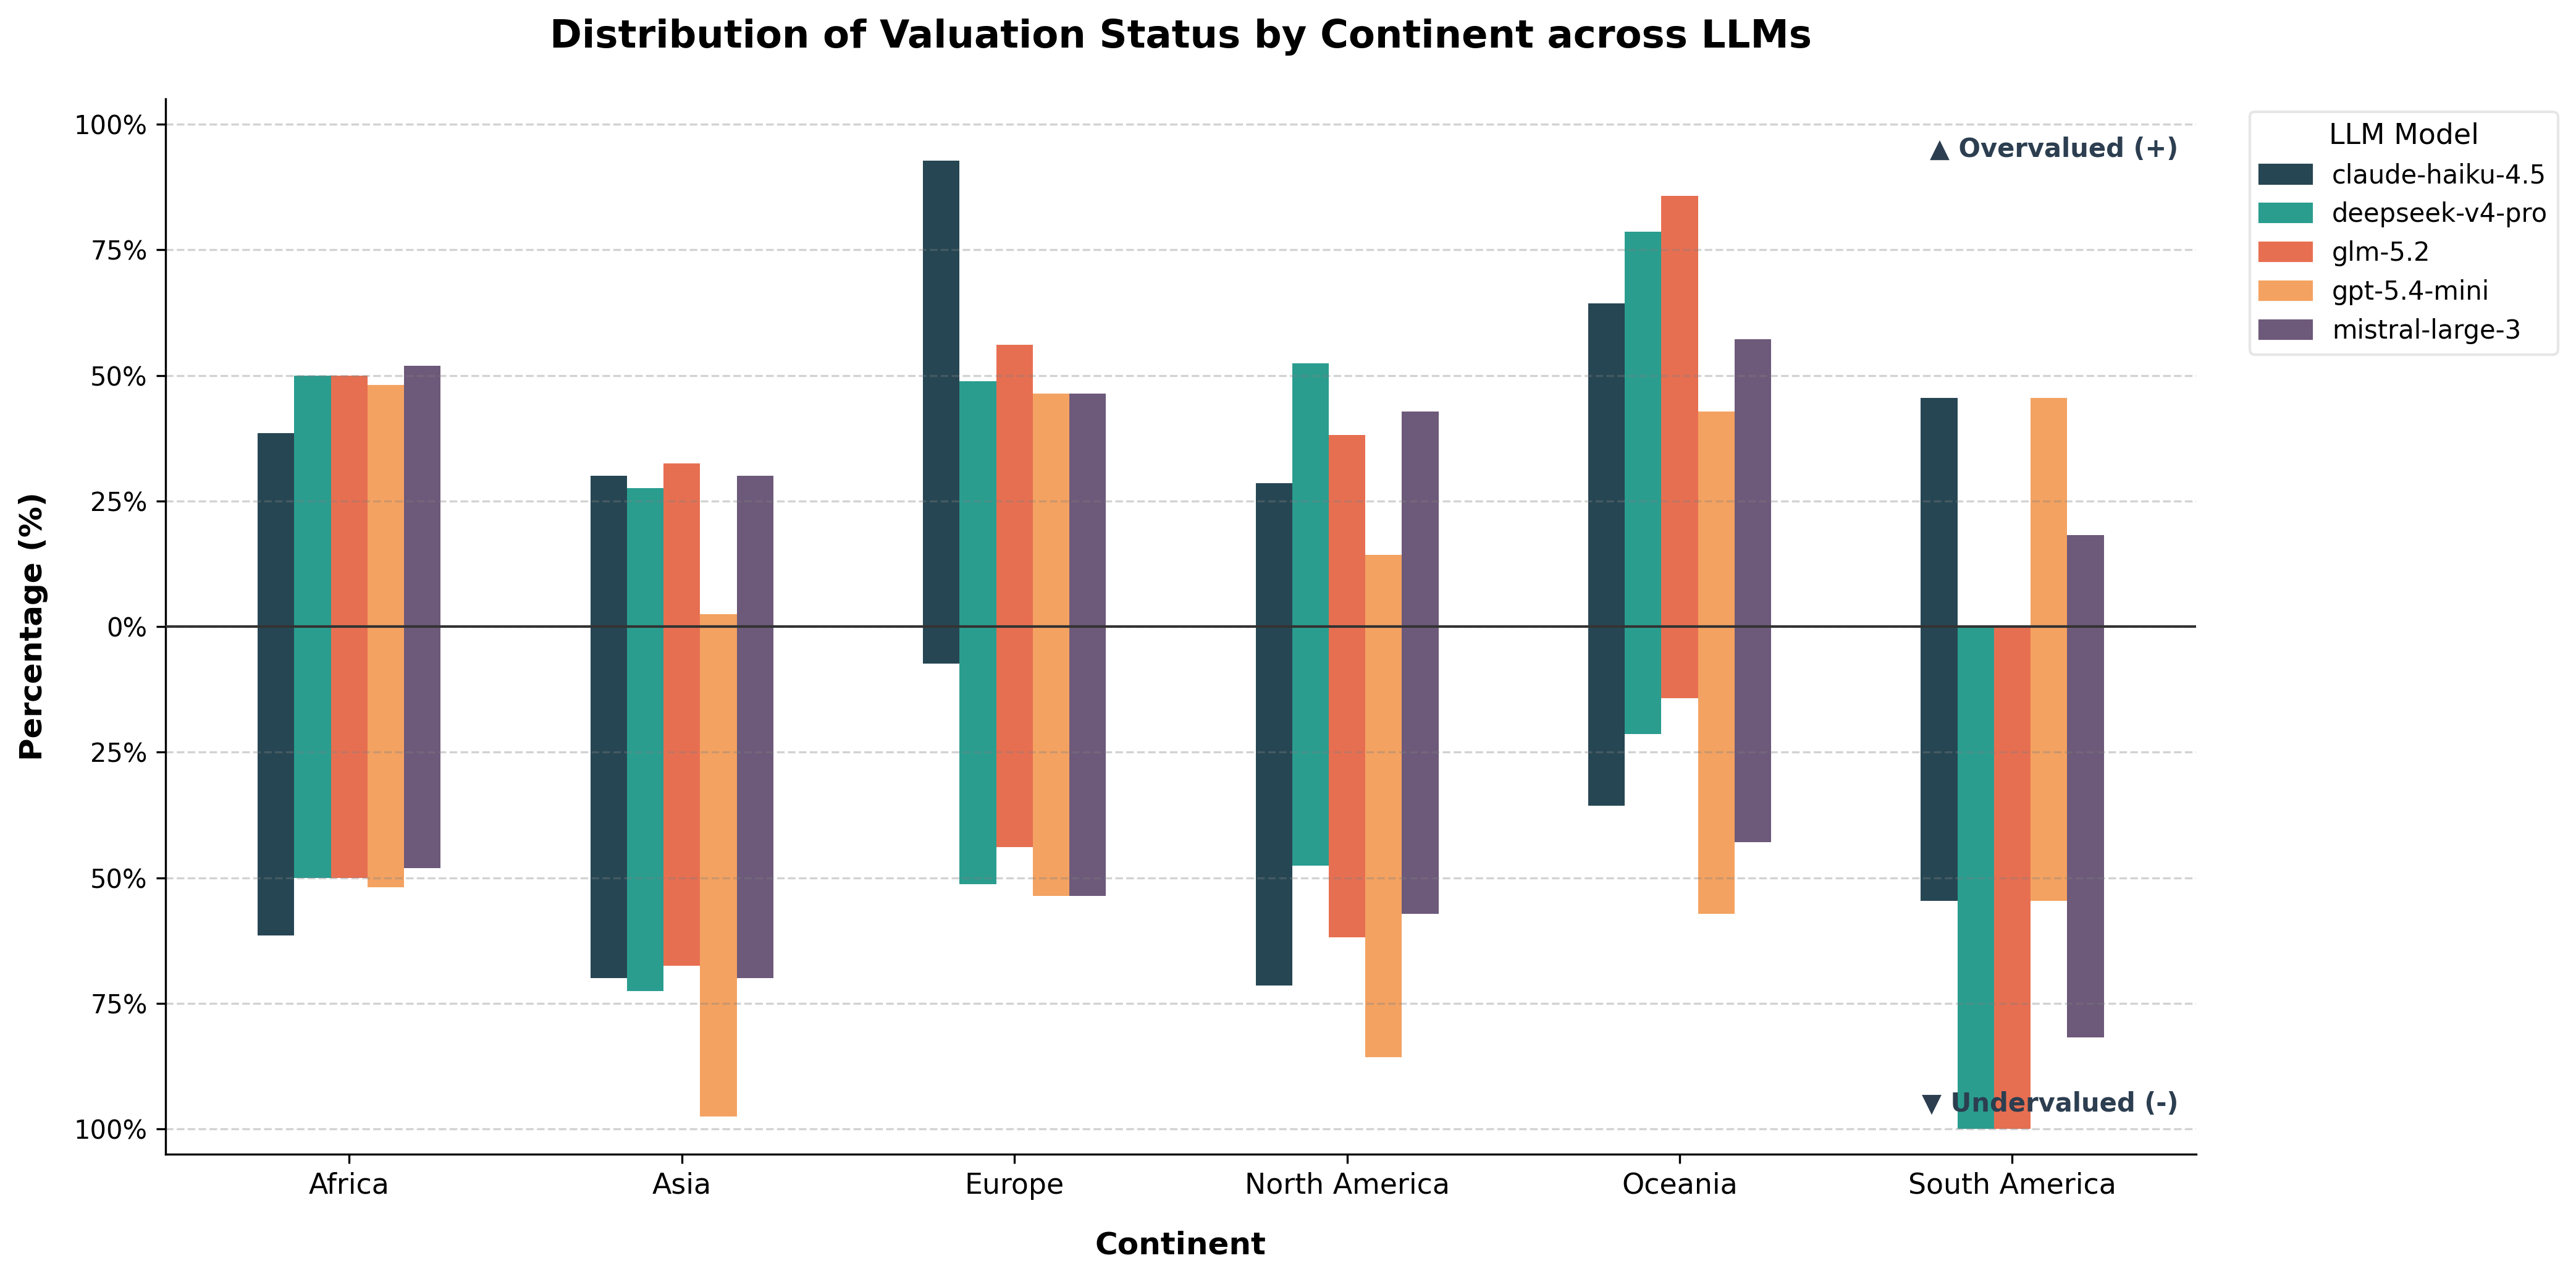

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import pickle
from pathlib import Path
import country_converter as coco
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter

# -------------------------------------------------------
# Load LLM results & setup paths
# -------------------------------------------------------
path_results = Path("results/country_2/rt2/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)

OUTPUT_DIR = Path("figures/world_map_mae")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Load GDP PPP dataset
# -------------------------------------------------------
excel_path = Path("193countries_GDP.csv")      # change this
df_gdp = pd.read_csv(excel_path)

# Keep only needed columns
df_gdp = df_gdp[["COUNTRY", "GPD (PPP)", "log"]]

# Map countries to the six continents
df_gdp["continent"] = coco.convert(names=df_gdp["COUNTRY"], to="continent_7")
df_gdp = df_gdp[df_gdp["continent"] != "Antarctica"]

# -------------------------------------------------------
# Process Data
# -------------------------------------------------------
summary_data = []
models = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

for model in models:
    df_llm = results[model].copy()
    
    # Ensure clean_transition is defined in your script
    df_llm["transition"] = df_llm["transition"].apply(clean_transition) 

    df = df_llm.merge(
        df_gdp,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna()

    x = df["log"].values
    y = df["transition"].values

    # Fit OLS regression
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()

    # Calculate Residuals & Categorize Status
    df["residual"] = ols_model.resid
    df["valuation_status"] = np.where(df["residual"] > 0, "Overvalued (+)", "Undervalued (-)")
    
    # Calculate percentages per continent
    for continent in df["continent"].unique():
        total_in_continent = len(df[df["continent"] == continent])
        overvalued_count = len(df[(df["continent"] == continent) & (df["valuation_status"] == "Overvalued (+)")])
        
        if total_in_continent > 0:
            over_pct = (overvalued_count / total_in_continent) * 100
            under_pct = 100 - over_pct
            summary_data.append({
                "Model": model,
                "Continent": continent,
                "Overvalued_Percentage": over_pct,
                "Undervalued_Percentage": under_pct
            })

df_plot = pd.DataFrame(summary_data)

# -------------------------------------------------------
# Plotting the Diverging Grouped Bar Chart
# -------------------------------------------------------
continents = sorted(df_plot["Continent"].unique())
n_continents = len(continents)
n_models = len(models)

# Positioning: Slimmer bar width (0.11)
x = np.arange(n_continents)
width = 0.11                 
total_width = width * n_models
offset_start = -total_width / 2 + width / 2 

fig, ax = plt.subplots(figsize=(14, 7), dpi=300)

# Modern, refined color scheme
model_colors = [
    "#264653",  # Deep Teal / Navy
    "#2A9D8F",  # Persian Green / Teal
    "#E76F51",  # Coral / Burnt Sienna
    "#F4A261",  # Sandy Amber
    "#6D597A"   # Muted Purple / Slate
]

for i, model in enumerate(models):
    offset = offset_start + i * width
    
    # Align data order
    model_data = df_plot[df_plot["Model"] == model].set_index("Continent").reindex(continents).fillna(0)
    
    over_pct = model_data["Overvalued_Percentage"].values
    under_pct = -1 * model_data["Undervalued_Percentage"].values
    
    # 1. Overvalued (Above x-axis, completely solid)
    ax.bar(
        x + offset, over_pct, width, 
        color=model_colors[i], alpha=1.0, edgecolor='none'
    )
           
    # 2. Undervalued (Below x-axis, completely solid, matching color)
    ax.bar(
        x + offset, under_pct, width, 
        color=model_colors[i], alpha=1.0, edgecolor='none'
    )

# -------------------------------------------------------
# Formatting & Legends
# -------------------------------------------------------
# Baseline separating overvalued and undervalued
ax.axhline(0, color='#333333', linewidth=1.0, zorder=3)

# Subtle background grid for easier value reading
ax.grid(axis='y', linestyle='--', alpha=0.35, color='gray', zorder=0)

# Labels and titles
ax.set_title("Distribution of Valuation Status by Continent across LLMs", fontsize=15, fontweight='bold', pad=20)
ax.set_xlabel("Continent", fontsize=12, fontweight='semibold', labelpad=12)
ax.set_ylabel("Percentage (%)", fontsize=12, fontweight='semibold', labelpad=10)

# Axis ticks
ax.set_xticks(x)
ax.set_xticklabels(continents, fontsize=11)
ax.set_ylim(-105, 105)

# Convert negative values on the axis to standard percentage strings
formatter = FuncFormatter(lambda y, pos: f"{abs(int(y))}%")
ax.yaxis.set_major_formatter(formatter)

# Explanatory annotations above and below the baseline
ax.text(n_continents - 0.5, 95, "▲ Overvalued (+)", ha="right", va="center", fontsize=10, fontweight="semibold", color="#2c3e50")
ax.text(n_continents - 0.5, -95, "▼ Undervalued (-)", ha="right", va="center", fontsize=10, fontweight="semibold", color="#2c3e50")

# Legend for models
model_patches = [mpatches.Patch(color=model_colors[i], label=model) for i, model in enumerate(models)]
ax.legend(
    handles=model_patches,
    title="LLM Model",
    title_fontsize='11',
    fontsize='10',
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    facecolor='white',
    edgecolor='#e0e0e0'
)

# Clean borders
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
# plt.savefig(OUTPUT_DIR / "diverging_valuation_by_continent.png", dpi=300, bbox_inches='tight')
plt.show()



#### Table: the percentage of overvalued countries (GDP_PPP)

In [74]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import pickle
from pathlib import Path
import country_converter as coco
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter

# -------------------------------------------------------
# Load LLM results & setup paths
# -------------------------------------------------------
path_results = Path("results/country_3/rt3/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)

OUTPUT_DIR = Path("figures/world_map_mae")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Load GDP PPP dataset
# -------------------------------------------------------
excel_path = Path("193countries_GDP.csv")      # change this
df_gdp = pd.read_csv(excel_path)

# Keep only needed columns
df_gdp = df_gdp[["COUNTRY", "GPD (PPP)", "log"]]

# Map countries to the six continents
df_gdp["continent"] = coco.convert(names=df_gdp["COUNTRY"], to="continent_7")
df_gdp = df_gdp[df_gdp["continent"] != "Antarctica"]

# -------------------------------------------------------
# Process Data
# -------------------------------------------------------
summary_data = []
models = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

for model in models:
    df_llm = results[model].copy()
    
    # Ensure clean_transition is defined in your script
    df_llm["transition"] = df_llm["transition"].apply(clean_transition) 

    df = df_llm.merge(
        df_gdp,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna()

    x = df["log"].values
    y = df["transition"].values

    # Fit OLS regression
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()

    # Calculate Residuals & Categorize Status
    df["residual"] = ols_model.resid
    df["valuation_status"] = np.where(df["residual"] > 0, "Overvalued (+)", "Undervalued (-)")
    
    # Calculate percentages per continent
    for continent in df["continent"].unique():
        total_in_continent = len(df[df["continent"] == continent])
        overvalued_count = len(df[(df["continent"] == continent) & (df["valuation_status"] == "Overvalued (+)")])
        
        if total_in_continent > 0:
            over_pct = (overvalued_count / total_in_continent) * 100
            under_pct = 100 - over_pct
            summary_data.append({
                "Model": model,
                "Continent": continent,
                "Overvalued_Percentage": over_pct,
                "Undervalued_Percentage": under_pct
            })

df_plot = pd.DataFrame(summary_data)
df_wide = df_plot.pivot(index="Model", columns="Continent", values="Overvalued_Percentage")

# Reorder rows to match your original model order
df_wide = df_wide.reindex(models)

# Format as "xx.x%"
df_wide_formatted = df_wide.map(lambda v: f"{v:.1f}%" if pd.notnull(v) else "")

df_wide_formatted = df_wide_formatted.reset_index()
print(df_wide_formatted)
# print(df_plot)



Continent             Model Africa   Asia Europe North America Oceania South America
0          claude-haiku-4.5  98.1%  67.5%  19.5%         85.7%   85.7%         72.7%
1           deepseek-v4-pro  55.8%  20.0%  51.2%         38.1%   92.9%          0.0%
2                   glm-5.2  55.8%  22.5%  56.1%         42.9%   57.1%          0.0%
3              gpt-5.4-mini  42.3%  22.5%  75.6%         42.9%   42.9%         45.5%
4           mistral-large-3   0.0%   0.0%   0.0%          0.0%    0.0%          0.0%


#### Table: the percentage of overvalued countries (GDP_PPP) : Three Prompts

In [28]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import pickle
from pathlib import Path
import country_converter as coco

models = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

# ---- GDP data (load once) ----
df_gdp = pd.read_csv(Path("193countries_GDP.csv"))[["COUNTRY", "GPD (PPP)", "log"]]
df_gdp["continent"] = coco.convert(names=df_gdp["COUNTRY"], to="continent_7")
df_gdp = df_gdp[df_gdp["continent"] != "Antarctica"]

# ---- One run -> wide table (models x continents) ----
def compute_wide(path_results):
    with open(path_results, "rb") as f:
        results = pickle.load(f)

    rows = []
    for model in models:
        df_llm = results[model].copy()
        df_llm["transition"] = df_llm["transition"].apply(clean_transition)  # your existing function

        df = df_llm.merge(df_gdp, left_on="country", right_on="COUNTRY", how="inner").dropna()

        X = sm.add_constant(df["log"].values)
        ols_model = sm.OLS(df["transition"].values, X).fit()
        df["over"] = ols_model.resid > 0

        for continent, g in df.groupby("continent"):
            rows.append({"Model": model, "Continent": continent,
                         "Overvalued_Percentage": g["over"].mean() * 100})

    wide = pd.DataFrame(rows).pivot(index="Model", columns="Continent",
                                    values="Overvalued_Percentage")
    return wide.reindex(models)

# ---- Run all three variations ----
paths = [
    Path("results/country_1/rt1/LR_results.pkl"),
    Path("results/country_2/rt2/LR_results.pkl"),
    Path("results/country_3/rt3/LR_results.pkl"),
]
variation_tables = [compute_wide(p) for p in paths]
assert len(variation_tables) >= 2, "Need at least 2 runs for a std"

# ---- Aggregate ----
stack = np.stack([t.values.astype(float) for t in variation_tables])   # (runs, models, continents)
continents = list(variation_tables[0].columns)

mean_df = pd.DataFrame(stack.mean(axis=0), index=models, columns=continents)
std_df  = pd.DataFrame(stack.std(axis=0, ddof=1), index=models, columns=continents)

per_run_model_mean = stack.mean(axis=1)                 # average over models, per run
mean_df.loc["Mean"] = per_run_model_mean.mean(axis=0)
std_df.loc["Mean"]  = per_run_model_mean.std(axis=0, ddof=1)

final = pd.DataFrame(
    [[f"{mean_df.loc[r, c]:.1f} ± {std_df.loc[r, c]:.1f}" for c in continents] for r in mean_df.index],
    index=mean_df.index, columns=continents)
print(final)

# ---- LaTeX (same to_latex function as before) ----
latex = to_latex(mean_df, std_df,
                 "Percentage of overvalued countries (positive OLS residual) per continent, mean $\\pm$ std over three variations.",
                 "tab:overvalued_continent")
print(latex)

                       Africa         Asia       Europe North America      Oceania South America
claude-haiku-4.5  62.2 ± 31.6  39.2 ± 25.0  52.8 ± 37.0   44.4 ± 36.1  61.9 ± 25.1   51.5 ± 18.9
deepseek-v4-pro    53.8 ± 3.3   25.0 ± 4.3   51.2 ± 2.4   39.7 ± 12.0   83.3 ± 8.2     0.0 ± 0.0
glm-5.2            53.2 ± 2.9   30.0 ± 6.6   56.9 ± 1.4    34.9 ± 9.9  69.0 ± 14.9     0.0 ± 0.0
gpt-5.4-mini       44.2 ± 3.3  19.2 ± 15.3  56.1 ± 16.9   33.3 ± 16.5   40.5 ± 4.1   54.5 ± 15.7
mistral-large-3   34.0 ± 29.4  18.3 ± 16.1  30.1 ± 26.1   34.9 ± 31.7  45.2 ± 40.6     9.1 ± 9.1
Mean               49.5 ± 1.6   26.3 ± 1.8   49.4 ± 8.8    37.5 ± 3.8   60.0 ± 5.2    23.0 ± 1.0
\begin{table}[t]
\centering
\small
\begin{tabular}{lcccccc}
\toprule
Model & Africa & Asia & Europe & North America & Oceania & South America \\
\midrule
claude-haiku-4.5 & 62.2$\pm$31.6 & 39.2$\pm$25.0 & 52.8$\pm$37.0 & 44.4$\pm$36.1 & 61.9$\pm$25.1 & 51.5$\pm$18.9 \\
deepseek-v4-pro & 53.8$\pm$3.3 & 25.0$\pm$4.3 & 51.

#### Table : the percentage of overvalued countries (Mean Income)

In [77]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import pickle
from pathlib import Path
import country_converter as coco
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter

# -------------------------------------------------------
# Load LLM results & setup paths
# -------------------------------------------------------
path_results = Path("results/country_1/rt1/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)

OUTPUT_DIR = Path("figures/world_map_mae")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Load GDP PPP dataset
# -------------------------------------------------------
excel_path = Path("mean_income.csv")      # change this
df_income = pd.read_csv(excel_path)

# Keep only needed columns
df_income = df_income[["COUNTRY", "Mean"]]

# Map countries to the six continents
df_income["continent"] = coco.convert(names=df_income["COUNTRY"], to="continent_7")
df_income = df_income[df_income["continent"] != "Antarctica"]

# -------------------------------------------------------
# Process Data
# -------------------------------------------------------
summary_data = []
models = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

for model in models:
    df_llm = results[model].copy()
    
    # Ensure clean_transition is defined in your script
    df_llm["transition"] = df_llm["transition"].apply(clean_transition) 

    df = df_llm.merge(
        df_income,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna()

    x = df["Mean"].values
    y = df["transition"].values

    # Fit OLS regression
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()

    # Calculate Residuals & Categorize Status
    df["residual"] = ols_model.resid
    df["valuation_status"] = np.where(df["residual"] > 0, "Overvalued (+)", "Undervalued (-)")
    
    # Calculate percentages per continent
    for continent in df["continent"].unique():
        total_in_continent = len(df[df["continent"] == continent])
        overvalued_count = len(df[(df["continent"] == continent) & (df["valuation_status"] == "Overvalued (+)")])
        
        if total_in_continent > 0:
            over_pct = (overvalued_count / total_in_continent) * 100
            under_pct = 100 - over_pct
            summary_data.append({
                "Model": model,
                "Continent": continent,
                "Overvalued_Percentage": over_pct,
                "Undervalued_Percentage": under_pct
            })

df_plot = pd.DataFrame(summary_data)
df_wide = df_plot.pivot(index="Model", columns="Continent", values="Overvalued_Percentage")

# Reorder rows to match your original model order
df_wide = df_wide.reindex(models)

# Format as "xx.x%"
df_wide_formatted = df_wide.map(lambda v: f"{v:.1f}%" if pd.notnull(v) else "")

df_wide_formatted = df_wide_formatted.reset_index()
print(df_wide_formatted)
# print(df_plot)



Continent             Model Africa   Asia Europe North America Oceania South America
0          claude-haiku-4.5  11.1%  48.1%  70.3%         20.0%    0.0%         55.6%
1           deepseek-v4-pro  18.5%  48.1%  67.6%         50.0%   66.7%          0.0%
2                   glm-5.2  70.4%  40.7%  56.8%         20.0%    0.0%         22.2%
3              gpt-5.4-mini  66.7%   7.4%  40.5%         20.0%    0.0%         44.4%
4           mistral-large-3  48.1%  48.1%  40.5%         20.0%   33.3%         22.2%


#### Table: the percentage of overvalued countries (Mean Income) : Three Prompts

In [70]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import pickle
from pathlib import Path
import country_converter as coco

models = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

# ---- GDP data (load once) ----
df_income = pd.read_csv(Path("mean_income.csv"))[["COUNTRY", "Mean"]]
df_income["continent"] = coco.convert(names=df_income["COUNTRY"], to="continent_7")
df_income = df_income[df_income["continent"] != "Antarctica"]

# ---- One run -> wide table (models x continents) ----
def compute_wide(path_results):
    with open(path_results, "rb") as f:
        results = pickle.load(f)

    rows = []
    for model in models:
        df_llm = results[model].copy()
        df_llm["transition"] = df_llm["transition"].apply(clean_transition)  # your existing function

        df = df_llm.merge(df_income, left_on="country", right_on="COUNTRY", how="inner").dropna()

        X = sm.add_constant(df["Mean"].values)
        ols_model = sm.OLS(df["transition"].values, X).fit()
        df["over"] = ols_model.resid > 0

        for continent, g in df.groupby("continent"):
            rows.append({"Model": model, "Continent": continent,
                         "Overvalued_Percentage": g["over"].mean() * 100})

    wide = pd.DataFrame(rows).pivot(index="Model", columns="Continent",
                                    values="Overvalued_Percentage")
    return wide.reindex(models)

# ---- Run all three variations ----
paths = [
    Path("results/country_1/rt1/LR_results.pkl"),
    Path("results/country_2/rt2/LR_results.pkl"),
    Path("results/country_3/rt3/LR_results.pkl"),
]
variation_tables = [compute_wide(p) for p in paths]
assert len(variation_tables) >= 2, "Need at least 2 runs for a std"

# ---- Aggregate ----
stack = np.stack([t.values.astype(float) for t in variation_tables])   # (runs, models, continents)
continents = list(variation_tables[0].columns)

mean_df = pd.DataFrame(stack.mean(axis=0), index=models, columns=continents)
std_df  = pd.DataFrame(stack.std(axis=0, ddof=1), index=models, columns=continents)

per_run_model_mean = stack.mean(axis=1)                 # average over models, per run
mean_df.loc["Mean"] = per_run_model_mean.mean(axis=0)
std_df.loc["Mean"]  = per_run_model_mean.std(axis=0, ddof=1)

final = pd.DataFrame(
    [[f"{mean_df.loc[r, c]:.1f} ± {std_df.loc[r, c]:.1f}" for c in continents] for r in mean_df.index],
    index=mean_df.index, columns=continents)
print(final)

# ---- LaTeX (same to_latex function as before) ----
latex = to_latex(mean_df, std_df,
                 "Percentage of overvalued countries (positive OLS residual) per continent, mean $\\pm$ std over three variations.",
                 "tab:overvalued_continent")
print(latex)

                       Africa         Asia       Europe North America      Oceania South America
claude-haiku-4.5  45.7 ± 44.8  54.3 ± 39.3  56.8 ± 13.5   40.0 ± 34.6  44.4 ± 38.5   70.4 ± 25.7
deepseek-v4-pro    27.2 ± 7.7   49.4 ± 2.1   65.8 ± 5.6   43.3 ± 11.5   66.7 ± 0.0     0.0 ± 0.0
glm-5.2            81.5 ± 9.8   42.0 ± 9.3   53.2 ± 3.1   30.0 ± 10.0    0.0 ± 0.0   11.1 ± 11.1
gpt-5.4-mini      43.2 ± 20.4  24.7 ± 15.4  52.3 ± 10.2   33.3 ± 11.5  22.2 ± 19.2   55.6 ± 19.2
mistral-large-3   65.4 ± 29.9  61.7 ± 33.6  65.8 ± 30.7   56.7 ± 40.4  44.4 ± 50.9   48.1 ± 44.9
Mean              52.6 ± 14.2  46.4 ± 15.0   58.7 ± 5.8   40.7 ± 18.9  35.6 ± 16.8   37.0 ± 10.5
\begin{table}[t]
\centering
\small
\begin{tabular}{lcccccc}
\toprule
Model & Africa & Asia & Europe & North America & Oceania & South America \\
\midrule
claude-haiku-4.5 & 45.7$\pm$44.8 & 54.3$\pm$39.3 & 56.8$\pm$13.5 & 40.0$\pm$34.6 & 44.4$\pm$38.5 & 70.4$\pm$25.7 \\
deepseek-v4-pro & 27.2$\pm$7.7 & 49.4$\pm$2.1 & 65.

#### Table: the percentage of overvalued countries (Patience)

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import pickle
from pathlib import Path
import country_converter as coco
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter

# -------------------------------------------------------
# Load LLM results & setup paths
# -------------------------------------------------------
path_results = Path("results/country_1/rt1/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)

OUTPUT_DIR = Path("figures/world_map_mae")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Load Patience dataset
# -------------------------------------------------------
df_patience = pd.read_excel(Path("patiencestudy.xlsx"))
df_patience["iso3"] = coco.convert(names=df_patience["COUNTRY"], to="ISO3", not_found=None)
# Map countries to the six continents
df_patience["continent"] = coco.convert(names=df_patience["COUNTRY"], to="continent_7")
df_patience = df_patience[df_patience["continent"] != "Antarctica"]


# -------------------------------------------------------
# Process Data
# -------------------------------------------------------
summary_data = []
models = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

for model in models:
    df_llm = results[model].copy()
    
    # Ensure clean_transition is defined in your script
    df_llm["transition"] = df_llm["transition"].apply(clean_transition) 

    df = df_llm.merge(
        df_patience,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna()

    x = df["patience"].values
    y = df["transition"].values

    # Fit OLS regression
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()

    # Calculate Residuals & Categorize Status
    df["residual"] = ols_model.resid
    df["valuation_status"] = np.where(df["residual"] > 0, "Overvalued (+)", "Undervalued (-)")
    
    # Calculate percentages per continent
    for continent in df["continent"].unique():
        total_in_continent = len(df[df["continent"] == continent])
        overvalued_count = len(df[(df["continent"] == continent) & (df["valuation_status"] == "Overvalued (+)")])
        
        if total_in_continent > 0:
            over_pct = (overvalued_count / total_in_continent) * 100
            under_pct = 100 - over_pct
            summary_data.append({
                "Model": model,
                "Continent": continent,
                "Overvalued_Percentage": over_pct,
                "Undervalued_Percentage": under_pct
            })

df_plot = pd.DataFrame(summary_data)
df_wide = df_plot.pivot(index="Model", columns="Continent", values="Overvalued_Percentage")

# Reorder rows to match your original model order
df_wide = df_wide.reindex(models)

# Format as "xx.x%"
df_wide_formatted = df_wide.map(lambda v: f"{v:.1f}%" if pd.notnull(v) else "")

df_wide_formatted = df_wide_formatted.reset_index()
print(df_wide_formatted)
# print(df_plot)

Continent             Model Africa   Asia Europe North America Oceania South America
0          claude-haiku-4.5  15.8%  45.2%  97.4%         30.0%  100.0%         50.0%
1           deepseek-v4-pro  10.5%  38.7%  74.4%         50.0%  100.0%         30.0%
2                   glm-5.2  10.5%  38.7%  69.2%         50.0%  100.0%         20.0%
3              gpt-5.4-mini   5.3%   3.2%  46.2%         40.0%   50.0%         50.0%
4           mistral-large-3  31.6%  45.2%  51.3%         40.0%  100.0%         30.0%


#### Compare the residuals per continent (step 2)

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import pickle
from pathlib import Path
import country_converter as coco
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter

# -------------------------------------------------------
# Load LLM results & setup paths
# -------------------------------------------------------
path_results = Path("results/country_1/rt1/LR_results.pkl")

with open(path_results, "rb") as f:
    results = pickle.load(f)

OUTPUT_DIR = Path("figures/world_map_mae")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# Load GDP PPP dataset
# -------------------------------------------------------
excel_path = Path("193countries_GDP.csv")      # change this
df_gdp = pd.read_csv(excel_path)

# Keep only needed columns
df_gdp = df_gdp[["COUNTRY", "GPD (PPP)", "log"]]

# Map countries to the six continents
df_gdp["continent"] = coco.convert(names=df_gdp["COUNTRY"], to="continent_7")
df_gdp = df_gdp[df_gdp["continent"] != "Antarctica"]

# -------------------------------------------------------
# Process Data (Summing Residuals)
# -------------------------------------------------------
summary_data = []
models = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

for model in models:
    df_llm = results[model].copy()
    
    # Ensure clean_transition is defined in your script
    df_llm["transition"] = df_llm["transition"].apply(clean_transition) 

    df = df_llm.merge(
        df_gdp,
        left_on="country",
        right_on="COUNTRY",
        how="inner"
    ).dropna()

    x = df["log"].values
    y = df["transition"].values

    # Fit OLS regression
    X = sm.add_constant(x)
    ols_model = sm.OLS(y, X).fit()

    # Calculate Residuals
    df["residual"] = ols_model.resid
    
    # Calculate summed residuals per continent
    for continent in df["continent"].unique():
        df_cont = df[df["continent"] == continent]
        
        # Sum of positive residuals (Overvalued)
        overvalued_sum = df_cont[df_cont["residual"] > 0]["residual"].sum()
        
        # Sum of negative residuals (Undervalued)
        undervalued_sum = df_cont[df_cont["residual"] < 0]["residual"].sum()
        
        summary_data.append({
            "Model": model,
            "Continent": continent,
            "Overvalued_Sum": overvalued_sum,
            "Undervalued_Sum": undervalued_sum
        })

df_plot = pd.DataFrame(summary_data)

# -------------------------------------------------------
# Plotting the Diverging Grouped Bar Chart
# -------------------------------------------------------
continents = sorted(df_plot["Continent"].unique())
n_continents = len(continents)
n_models = len(models)

# Positioning
x = np.arange(n_continents)
width = 0.11                 
total_width = width * n_models
offset_start = -total_width / 2 + width / 2 

fig, ax = plt.subplots(figsize=(14, 7), dpi=300)

# Modern, refined color scheme
model_colors = ["#264653", "#2A9D8F", "#E76F51", "#F4A261", "#6D597A"]

for i, model in enumerate(models):
    offset = offset_start + i * width
    
    # Align data order
    model_data = df_plot[df_plot["Model"] == model].set_index("Continent").reindex(continents).fillna(0)
    
    over_sum = model_data["Overvalued_Sum"].values
    under_sum = model_data["Undervalued_Sum"].values # Inherently negative
    
    # 1. Overvalued (Above x-axis)
    ax.bar(
        x + offset, over_sum, width, 
        color=model_colors[i], alpha=1.0, edgecolor='none'
    )
           
    # 2. Undervalued (Below x-axis)
    ax.bar(
        x + offset, under_sum, width, 
        color=model_colors[i], alpha=1.0, edgecolor='none'
    )

# -------------------------------------------------------
# Formatting & Legends
# -------------------------------------------------------
# Baseline separating overvalued and undervalued
ax.axhline(0, color='#333333', linewidth=1.0, zorder=3)
ax.grid(axis='y', linestyle='--', alpha=0.35, color='gray', zorder=0)

# Labels and titles
ax.set_title("Sum of Residuals (Overvalued vs Undervalued) by Continent across LLMs", fontsize=15, fontweight='bold', pad=20)
ax.set_xlabel("Continent", fontsize=12, fontweight='semibold', labelpad=12)
ax.set_ylabel("Sum of Residuals (USD)", fontsize=12, fontweight='semibold', labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(continents, fontsize=11)

# Dynamically set symmetric y-limits based on the largest absolute sum of residuals
max_val = max(df_plot["Overvalued_Sum"].max(), abs(df_plot["Undervalued_Sum"].min()))
padding = max_val * 0.15
y_lim = max_val + padding
ax.set_ylim(-y_lim, y_lim)

# Convert negative values on the axis to absolute standard numbers
formatter = FuncFormatter(lambda y, pos: f"{abs(y):g}")
ax.yaxis.set_major_formatter(formatter)

# Explanatory annotations 
ax.text(n_continents - 0.5, y_lim * 0.9, "▲ Overvalued (+)", ha="right", va="center", fontsize=10, fontweight="semibold", color="#2c3e50")
ax.text(n_continents - 0.5, -y_lim * 0.9, "▼ Undervalued (-)", ha="right", va="center", fontsize=10, fontweight="semibold", color="#2c3e50")

# Legend for models
model_patches = [mpatches.Patch(color=model_colors[i], label=model) for i, model in enumerate(models)]
ax.legend(
    handles=model_patches,
    title="LLM Model",
    title_fontsize='11',
    fontsize='10',
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    facecolor='white',
    edgecolor='#e0e0e0'
)

# Clean borders
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sum_residuals_by_continent.png", dpi=300, bbox_inches='tight')
plt.show()

#### Residual map: plot them on maps (step 3)

In [ ]:
import pickle
import pandas as pd
import plotly.express as px
from pathlib import Path

# -------------------------------------------------------
# 1. Setup Directories and File Paths
# -------------------------------------------------------
PLOT_DIR = Path("figures/world_map_residuals")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Path to the master CSV generated in the previous step
csv_path = Path("figures/world_map_residuals/master_residuals_all_models.csv")

# Load master residual DataFrame
df = pd.read_csv(csv_path)

# -------------------------------------------------------
# 2. Define the Adapted Plotting Function
# -------------------------------------------------------
def plot_residual_values(
    df: pd.DataFrame,
    title: str,
    out_html: Path | None = None,
    out_png: Path | None = None
):
    """
    Takes a DataFrame with 'COUNTRY' and 'residual' columns.
    Generates a choropleth map using a diverging color scale centered at 0.
    """
    plot_df = df.copy()
    
    # Create the choropleth map
    fig = px.choropleth(
        plot_df,
        locations="COUNTRY",
        locationmode="country names",  # Maps standard country names directly
        color="residual",
        color_continuous_scale="RdBu", # Diverging scale (Red = Undervalued, Blue = Overvalued)
        color_continuous_midpoint=0,     # Centers 0 (zero deviation) at the neutral mid-point
        range_color=(-14, 14),           # Symmetric range across positive and negative bounds
        title=title,
        labels={"residual": "Valuation Deviation <br>(Dollar)"}, 
        projection="natural earth",
    )
    
    # Adjust visual styling
    fig.update_layout(
        title_font=dict(size=18),
        margin=dict(l=0, r=0, t=40, b=0),
        coloraxis_colorbar=dict(
            title_font=dict(size=10),
            tickfont=dict(size=10)
        )
    )
    
    # Save interactive HTML
    if out_html:
        fig.write_html(str(out_html), include_plotlyjs="cdn")
        
    # Save high-resolution static PNG
    if out_png:
        fig.write_image(str(out_png), scale=2)
        
    return fig

# -------------------------------------------------------
# 3. Iterate Across Models and Plot Maps
# -------------------------------------------------------

for model in models:
    target_col = f"{model}"
    
    # if target_col not in df.columns:
    #     print(f"Warning: Column '{target_col}' not found in CSV. Skipping {model}.")
    #     continue

    # Filter 'COUNTRY' and model specific residual column, then standardize column name
    df_model = df[["COUNTRY", target_col]].dropna().rename(columns={target_col: "residual"})

    # Set output paths
    out_html = PLOT_DIR / f"world_map_residual_{model}.html"
    out_png = PLOT_DIR / f"World_Map_Residual_{model}.png"

    # Generate the map
    fig = plot_residual_values(
        df=df_model, 
        title=f"Worldwide Valuation Deviation ($) ({model})", 
        # out_html=out_html,
        # out_png=out_png
    )

    fig.show()

## MAE

### Check isotonic regression and MAEs

In [ ]:
from pathlib import Path
import pickle
import os
import numpy as np
from scipy import stats
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, r2_score

os.chdir(r"C:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience")

path_results1 = Path("results/country_1/rt1/data.pkl")
with open(path_results1, "rb") as f:
    df1 = pickle.load(f)

models= ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]

# Updated list of 10 countries
# country_name = [
#     "Afghanistan", "Belgium", "Brazil", "China", "France", 
#     "India", "Switzerland", "United States", "Vietnam", "Zimbabwe"
# ]

country_name = ["China"]

# Define the helper function OUTSIDE the loop
def process_data(df, target_country):
    # Filter by country
    df_filtered = df[df['country'] == target_country].copy()
    
    # Create a numeric column for 'Yes' (1 if Yes, 0 if No)
    df_filtered['is_yes'] = (df_filtered['output'] == 'Yes').astype(int)
    
    # Group by reward_value and calculate the percentage of 'Yes'
    summary = df_filtered.groupby('reward_value')['is_yes'].mean() * 100
    
    return summary

# Dictionary to track the average MAE for each model
model_avg_maes = {}

for i in models:
    df1_model = df1[i]
    
    # List to collect MAE values for this specific model across all countries
    current_model_maes = []

    for c in country_name:
        # Process datasets using the current country 'c'
        summary1 = process_data(df1_model, c)
        
        # Skip if the country is not present in the data for this model
        if summary1.empty:
            print(f"Skipping {c} for model {i} - no data found.")
            continue
            
        reward_values = np.array(summary1.index)
        yes_percentages = np.array(summary1.values)

        iso_reg = IsotonicRegression(increasing=True) 
        # Fit the model and generate the "perfectly monotonic" Y values
        y_isotonic = iso_reg.fit_transform(reward_values, yes_percentages)
        
        # --- Calculate Metrics ---
        mae = mean_absolute_error(yes_percentages, y_isotonic)
        r2 = r2_score(yes_percentages, y_isotonic)
        
        # Append this country's MAE to our tracker list
        current_model_maes.append(mae)

        # --- Print Results ---
        print(f"--- Isotonic Metrics {c} x {i} ---")
        print(f"MAE (Turbulence Penalty): {mae:.4f}")
        print(f"R-squared (Fit Quality):  {r2:.4f}\n")
    
    # Calculate the average MAE for the model and save it to the dictionary
    if current_model_maes: 
        model_avg_maes[i] = np.mean(current_model_maes)

# Print the final summary block
print("=" * 50)
print("FINAL SUMMARY: Average MAE across all 10 countries")
print("=" * 50)
for model, avg_mae in model_avg_maes.items():
    print(f"Model: {model:<20} | Avg MAE: {avg_mae:.4f}")

--- Isotonic Metrics China x claude-haiku-4.5 ---
MAE (Turbulence Penalty): 8.8889
R-squared (Fit Quality):  0.2120

--- Isotonic Metrics China x deepseek-v4-pro ---
MAE (Turbulence Penalty): 1.8000
R-squared (Fit Quality):  0.9717

--- Isotonic Metrics China x glm-5.2 ---
MAE (Turbulence Penalty): 0.5333
R-squared (Fit Quality):  0.9938

--- Isotonic Metrics China x gpt-5.4-mini ---
MAE (Turbulence Penalty): 0.0000
R-squared (Fit Quality):  1.0000

--- Isotonic Metrics China x mistral-large-3 ---
MAE (Turbulence Penalty): 14.5095
R-squared (Fit Quality):  0.6462

FINAL SUMMARY: Average MAE across all 10 countries
Model: claude-haiku-4.5     | Avg MAE: 8.8889
Model: deepseek-v4-pro      | Avg MAE: 1.8000
Model: glm-5.2              | Avg MAE: 0.5333
Model: gpt-5.4-mini         | Avg MAE: 0.0000
Model: mistral-large-3      | Avg MAE: 14.5095


### MAE world maps

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import plotly.express as px
from pathlib import Path
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, r2_score

# ==========================================
# 0. Setup Directories & Load Data
# ==========================================
os.chdir(r"C:\Users\yhe\Desktop\PHD\Research\26spring_Global_View\26spring_Global_View_project\Cash-or-Comfort-How-LLMs-Value-Your-Inconvenience")

path_results = Path("results/country_1/rt1/data.pkl")
path_country_list = Path("config/country_list_full.txt")

PLOT_DIR = Path("figures/world_map_mae")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# 1) Extract country names from txt file
with open(path_country_list, "r", encoding="utf-8") as f:
    # Read lines, strip whitespace, and ignore empty lines
    country_name = [line.strip() for line in f if line.strip()]

# Load model output data
with open(path_results, "rb") as f:
    df1 = pickle.load(f)

# models = ['claude-haiku-4.5', 'mistral-large-3', 'gpt-5.4-mini', 'glm-5.2', 'deepseek-v4-pro']
models = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]
# ==========================================
# 1. Define Helper Functions
# ==========================================
def process_data(df, target_country):
    """Filters data for a specific country and calculates the % of 'Yes' answers."""
    df_filtered = df[df['country'] == target_country].copy()
    df_filtered['is_yes'] = (df_filtered['output'] == 'Yes').astype(int)
    summary = df_filtered.groupby('reward_value')['is_yes'].mean() * 100
    return summary

def plot_mae_values(df: pd.DataFrame, title: str, out_html: None, out_png: None):
    """
    Takes a DataFrame with 'country' and 'MAE' columns.
    Creates a choropleth map, saves as HTML and high-res PNG.
    """
    fig = px.choropleth(
        df,
        locations="country",
        locationmode="country names",
        color="MAE",
        color_continuous_scale="Reds", 
        range_color=(1, 25), 
        title=title,
        labels={"MAE": "MAE<br>(Turbulence Degree)"}, 
        projection="natural earth",
    )
    
    fig.update_layout(
        title_font=dict(size=20),
        margin=dict(l=0, r=0, t=40, b=0),
        coloraxis_colorbar=dict(title_font=dict(size=20), tickfont=dict(size=20))
    )
    
    # Save Interactive HTML
    if out_html:
        fig.write_html(out_html, include_plotlyjs="cdn")
        
    # Save High-Res PNG
    if out_png:
        fig.write_image(out_png, scale=2)

    return fig

# ==========================================
# 2. Main Loop: Calculate MAE & Plot Maps
# ==========================================
model_avg_maes = {}

for i in models:
    print(f"\nProcessing Model: {i}...")
    df1_model = df1[i]
    
    # List to collect MAE dictionaries for the current model
    model_data = []

    for c in country_name:
        summary1 = process_data(df1_model, c)
        
        # Skip if the country is not present in the data
        if summary1.empty:
            continue
            
        reward_values = np.array(summary1.index)
        yes_percentages = np.array(summary1.values)

        # Fit Isotonic Regression
        iso_reg = IsotonicRegression(increasing=True) 
        y_isotonic = iso_reg.fit_transform(reward_values, yes_percentages)
        
        # Calculate Metric
        mae = mean_absolute_error(yes_percentages, y_isotonic)
        
        # Store for mapping
        model_data.append({"country": c, "MAE": mae})

    # Convert the collected data into a DataFrame for Plotly
    df_model_mae = pd.DataFrame(model_data)
    
    if not df_model_mae.empty:
        # Calculate the final average MAE for this model
        avg_mae = df_model_mae["MAE"].mean()
        model_avg_maes[i] = avg_mae
        print(f"--> Average MAE calculated: {avg_mae:.4f}")

        # Define output filenames
        html_file = str(PLOT_DIR / f"wmu_{i}.html".replace(" ", "_"))
        png_file = PLOT_DIR / f"wmu_{i}.png".replace(" ", "_")
        
        # 3. Generate the Map
        fig = plot_mae_values(
            df=df_model_mae,
            title=f"Worldwide LLMs Response Uncertainty ({i})",
            out_html=None,
            out_png=None
        )
        
        # Optional: display in script execution 
        fig.show()

# ==========================================
# 4. Final Summary Output
# ==========================================
print("\n" + "=" * 50)
print("FINAL SUMMARY: Average MAE across all mapped countries")
print("=" * 50)
for model, avg_mae in model_avg_maes.items():
    print(f"Model: {model:<20} | Avg MAE: {avg_mae:.4f}")

### MAE per continent

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import plotly.express as px
from pathlib import Path
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_absolute_error, r2_score

# ==========================================
# 0. Setup Directories & Load Data
# ==========================================

path_results = Path("results/country_1/rt1/data.pkl")
path_country_list = Path("config/country_list_full.txt")

# 1) Extract country names from txt file
with open(path_country_list, "r", encoding="utf-8") as f:
    # Read lines, strip whitespace, and ignore empty lines
    country_name = [line.strip() for line in f if line.strip()]

# Load model output data
with open(path_results, "rb") as f:
    df1 = pickle.load(f)

# models = ['claude-haiku-4.5', 'mistral-large-3', 'gpt-5.4-mini', 'glm-5.2', 'deepseek-v4-pro']
models = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]
# ==========================================
# 1. Define Helper Functions
# ==========================================
def process_data(df, target_country):
    """Filters data for a specific country and calculates the % of 'Yes' answers."""
    df_filtered = df[df['country'] == target_country].copy()
    df_filtered['is_yes'] = (df_filtered['output'] == 'Yes').astype(int)
    summary = df_filtered.groupby('reward_value')['is_yes'].mean() * 100
    return summary

# ==========================================
# 2. Main Loop: Calculate MAE & Plot Maps
# ==========================================
CONT = ["Africa", "Asia", "Europe", "North America", "South America", "Oceania"]

model_avg_maes = {}
model_cont_maes = {}   # NEW
model_n = {}           # NEW

for i in models:
    print(f"\nProcessing Model: {i}...")
    df1_model = df1[i]
    
    
    # List to collect MAE dictionaries for the current model
    model_data = []

    for c in country_name:
        summary1 = process_data(df1_model, c)
        
        # Skip if the country is not present in the data
        if summary1.empty:
            continue
            
        reward_values = np.array(summary1.index)
        yes_percentages = np.array(summary1.values)

        # Fit Isotonic Regression
        iso_reg = IsotonicRegression(increasing=True) 
        y_isotonic = iso_reg.fit_transform(reward_values, yes_percentages)
        
        # Calculate Metric
        mae = mean_absolute_error(yes_percentages, y_isotonic)
        
        # Store for mapping
        model_data.append({"country": c, "MAE": mae})

    # Convert the collected data into a DataFrame for Plotly
    df_model_mae = pd.DataFrame(model_data)
    df_model_mae["continent"] = coco.convert(names=df_model_mae["country"], to="continent_7")
    
    if not df_model_mae.empty:
        # Calculate the final average MAE for this model
        avg_mae = df_model_mae["MAE"].mean()
        model_avg_maes[i] = avg_mae
        model_cont_maes[i] = df_model_mae.groupby("continent")["MAE"].mean()   # NEW
        model_n[i] = len(df_model_mae)   

# ==========================================
# 4. Final Summary Output
# ==========================================
# print("\n" + "=" * 50)
# print("FINAL SUMMARY: Average MAE across all mapped countries")
# print("=" * 50)
# for model, avg_mae in model_avg_maes.items():
#     print(f"Model: {model:<20} | Avg MAE: {avg_mae:.4f}")
# ==========================================
# 4. Final Summary Output
# ==========================================
rows = []
for m, avg in model_avg_maes.items():
    row = {"Model": m, "Mean MAE": f"{avg:.2f}"}
    for c in CONT:
        v = model_cont_maes[m].get(c, np.nan)
        if pd.isna(v):
            row[c] = "n/a"
        else:
            row[c] = f"{v:.2f} ({'+' if v > avg else '-'})"
    row["N countries"] = model_n[m]
    rows.append(row)

summary_df = pd.DataFrame(rows)

print("\n" + "=" * 100)
print("FINAL SUMMARY: Mean MAE overall and by continent  (+/-: above/below the model's mean)")
print("=" * 100)
print(summary_df.to_string(index=False))


Processing Model: claude-haiku-4.5...

Processing Model: deepseek-v4-pro...

Processing Model: glm-5.2...

Processing Model: gpt-5.4-mini...

Processing Model: mistral-large-3...

FINAL SUMMARY: Mean MAE overall and by continent  (+/-: above/below the model's mean)
           Model Mean MAE    Africa      Asia    Europe North America South America   Oceania  N countries
claude-haiku-4.5     9.18  6.88 (-) 11.74 (+)  5.19 (-)     13.30 (+)     16.03 (+)  9.56 (+)          193
 deepseek-v4-pro     1.25  0.60 (-)  1.33 (+)  2.10 (+)      1.05 (-)      0.72 (-)  1.67 (+)          193
         glm-5.2     1.63  0.35 (-)  1.42 (-)  3.46 (+)      1.82 (+)      0.69 (-)  2.07 (+)          193
    gpt-5.4-mini     1.36  0.57 (-)  0.72 (-)  2.75 (+)      1.75 (+)      1.27 (-)  1.62 (+)          193
 mistral-large-3    12.37 13.45 (+) 11.72 (-) 12.01 (-)     11.67 (-)     11.80 (-) 13.15 (+)          193


### Pearson correlation between worldmap and MAE worldmap


Processing Model: claude-haiku-4.5...
  Pearson r = 0.065 (p = 0.3706, n = 193)


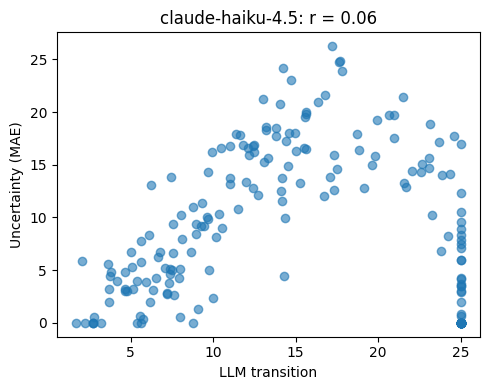


Processing Model: deepseek-v4-pro...
  Pearson r = 0.722 (p = 1.963e-32, n = 193)


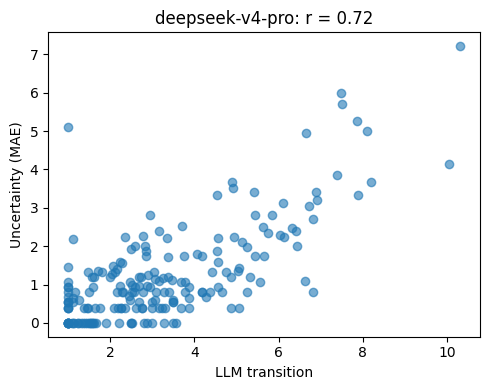


Processing Model: glm-5.2...
  Pearson r = 0.872 (p = 3.664e-61, n = 193)


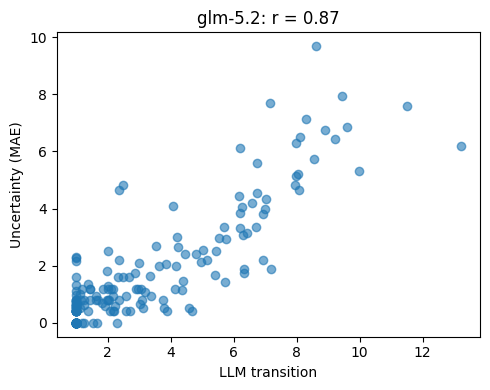


Processing Model: gpt-5.4-mini...
  Pearson r = 0.608 (p = 6.425e-21, n = 193)


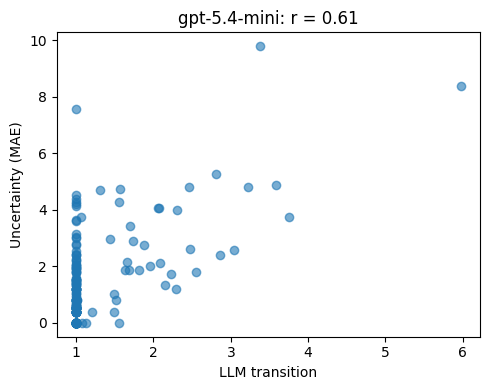


Processing Model: mistral-large-3...
  Pearson r = 0.284 (p = 6.092e-05, n = 193)


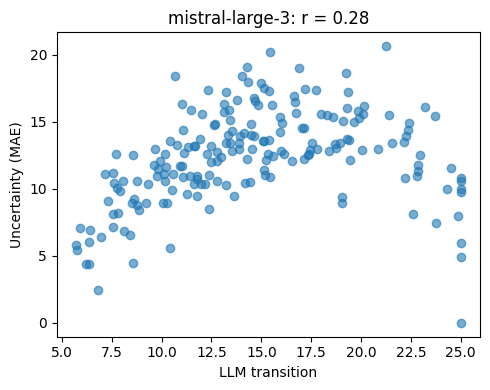

           model  n_countries  pearson_r  p_value  ci_low  ci_high
claude-haiku-4.5          193     0.0648   0.3706 -0.0771   0.2042
 deepseek-v4-pro          193     0.7224   0.0000  0.6472   0.7837
         glm-5.2          193     0.8720   0.0000  0.8334   0.9021
    gpt-5.4-mini          193     0.6083   0.0000  0.5110   0.6902
 mistral-large-3          193     0.2845   0.0001  0.1492   0.4093


In [ ]:
from scipy.stats import pearsonr
import matplotlib.pyplot as plt


# ==========================================
# 0. Setup Directories & Load Data
# ==========================================

path_results = Path("results/country_1/rt1/data.pkl")
path_country_list = Path("config/country_list_full.txt")
path_LRresults = Path("results/country_1/rt1/LR_results.pkl")

# PLOT_DIR = Path("figures/world_map_mae")

# Extract country names from txt file
with open(path_country_list, "r", encoding="utf-8") as f:
    # Read lines, strip whitespace, and ignore empty lines
    country_name = [line.strip() for line in f if line.strip()]

# Load model output data
with open(path_results, "rb") as f:
    df1 = pickle.load(f)

# Load model output data: this is LLMs' response
with open(path_LRresults, "rb") as f:
    dfLR = pickle.load(f)


# models = ['gpt-5.4-mini' ]
models = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]

# ==========================================
# 1. Define Helper Functions
# ==========================================
def process_data(df, target_country):
    """Filters data for a specific country and calculates the % of 'Yes' answers."""
    df_filtered = df[df['country'] == target_country].copy()
    df_filtered['is_yes'] = (df_filtered['output'] == 'Yes').astype(int)
    summary = df_filtered.groupby('reward_value')['is_yes'].mean() * 100
    return summary

# ==========================================
# 2. Main Loop: Calculate MAE
# ==========================================
corr_results = []

for i in models:
    print(f"\nProcessing Model: {i}...")
    df1_model = df1[i]
    
    # List to collect MAE dictionaries for the current model
    model_data = []

    for c in country_name:
        summary1 = process_data(df1_model, c)
        
        # Skip if the country is not present in the data
        if summary1.empty:
            continue
            
        reward_values = np.array(summary1.index)
        yes_percentages = np.array(summary1.values)

        # Fit Isotonic Regression
        iso_reg = IsotonicRegression(increasing=True) 
        y_isotonic = iso_reg.fit_transform(reward_values, yes_percentages)
        
        # Calculate Metric
        mae = mean_absolute_error(yes_percentages, y_isotonic)
        
        # Store for mapping
        model_data.append({"country": c, "MAE": mae})

    # This is LLMs response uncertainty (MAE) for each country
    df_model_mae = pd.DataFrame(model_data)

    # ---- Pearson correlation: response vs. uncertainty (MAE) ----
    df_resp = dfLR[i]

    # Clean the 'transition' column: convert >25 and <1 to numeric
    df_resp["transition"] = df_resp["transition"].astype(str).str.replace(r"[<>]", "", regex=True).astype(float)

    # filterout all countris with a transition that is equal to 1.0 and 25.0
    # df_resp = df_resp[(df_resp["transition"] > 1.0) & (df_resp["transition"] < 25.0)]

    merged = df_model_mae.merge(df_resp, on="country", how="inner").dropna()

    res = pearsonr(merged["transition"], merged["MAE"])
    ci = res.confidence_interval(confidence_level=0.95)

    corr_results.append({
        "model": i,
        "n_countries": len(merged),
        "pearson_r": res.statistic,
        "p_value": res.pvalue,
        "ci_low": ci.low,
        "ci_high": ci.high,
    })
    print(f"  Pearson r = {res.statistic:.3f} (p = {res.pvalue:.4g}, n = {len(merged)})")

    # Scatterplot for a quick visual check
    plt.figure(figsize=(5, 4))
    plt.scatter(merged["transition"], merged["MAE"], alpha=0.6)
    plt.xlabel("LLM transition")
    plt.ylabel("Uncertainty (MAE)")
    plt.title(f"{i}: r = {res.statistic:.2f}")
    plt.tight_layout()
    plt.show()

df_corr = pd.DataFrame(corr_results)
print(df_corr.round(4).to_string(index=False))

### Pearson correlation between Gini and MAE worldmap

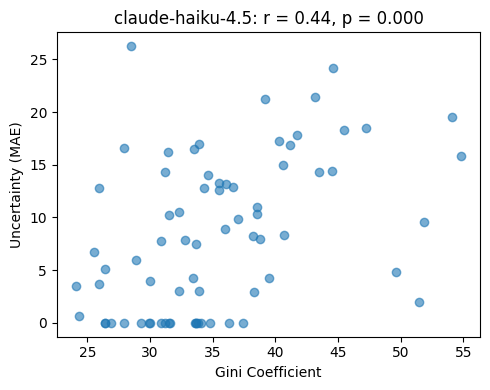

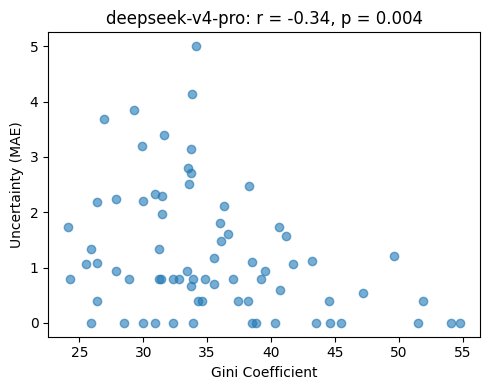

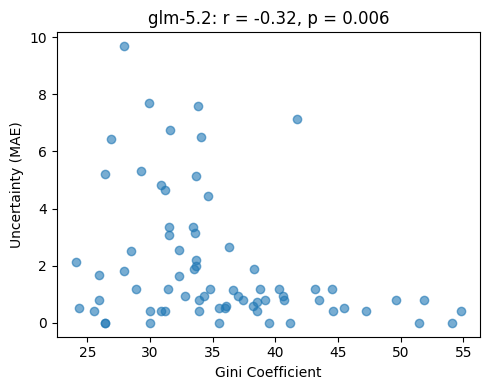

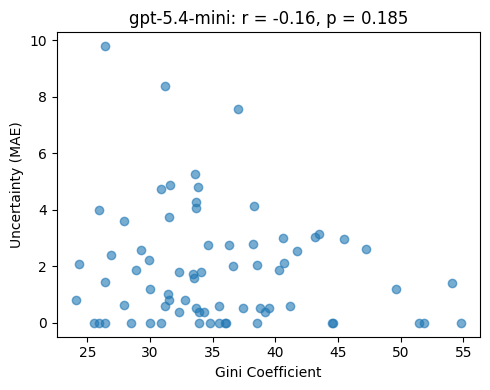

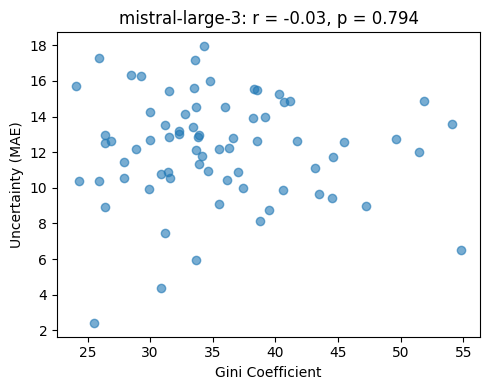

           model  n_countries  pearson_r  p_value
claude-haiku-4.5           72      0.435    0.000
 deepseek-v4-pro           72     -0.337    0.004
         glm-5.2           72     -0.320    0.006
    gpt-5.4-mini           72     -0.158    0.185
 mistral-large-3           72     -0.031    0.794


In [ ]:
from scipy.stats import pearsonr
import matplotlib.pyplot as plt


# ==========================================
# 0. Setup Directories & Load Data
# ==========================================

path_results = Path("results/country_1/rt1/data.pkl")
path_country_list = Path("config/country_list_full.txt")
path_gini = Path("gini.xls")

PLOT_DIR = Path("figures/gini")

# Extract country names from txt file
with open(path_country_list, "r", encoding="utf-8") as f:
    # Read lines, strip whitespace, and ignore empty lines
    country_name = [line.strip() for line in f if line.strip()]

# Load model output data
with open(path_results, "rb") as f:
    df1 = pickle.load(f)

# Load Gini coefficient data
df_gini= pd.read_excel(path_gini)
df_gini["iso3"] = coco.convert(names=df_gini["COUNTRY"], to="ISO3", not_found=None)

# models = ['gpt-5.4-mini' ]
models = ['claude-haiku-4.5', 'deepseek-v4-pro','glm-5.2','gpt-5.4-mini',  'mistral-large-3' ]

# ==========================================
# 1. Define Helper Functions
# ==========================================
def process_data(df, target_country):
    """Filters data for a specific country and calculates the % of 'Yes' answers."""
    df_filtered = df[df['country'] == target_country].copy()
    df_filtered['is_yes'] = (df_filtered['output'] == 'Yes').astype(int)
    summary = df_filtered.groupby('reward_value')['is_yes'].mean() * 100
    return summary

# ==========================================
# 2. Main Loop: Calculate MAE
# ==========================================

corr_results = []

for i in models:
    # print(f"\nProcessing Model: {i}...")
    df1_model = df1[i]
    
    # List to collect MAE dictionaries for the current model
    model_data = []

    for c in country_name:
        summary1 = process_data(df1_model, c)
        
        # Skip if the country is not present in the data
        if summary1.empty:
            continue
            
        reward_values = np.array(summary1.index)
        yes_percentages = np.array(summary1.values)

        # Fit Isotonic Regression
        iso_reg = IsotonicRegression(increasing=True) 
        y_isotonic = iso_reg.fit_transform(reward_values, yes_percentages)
        
        # Calculate Metric
        mae = mean_absolute_error(yes_percentages, y_isotonic)
        
        # Store for mapping
        model_data.append({"country": c, "MAE": mae})

    # This is LLMs response uncertainty (MAE) for each country
    df_model_mae = pd.DataFrame(model_data)
    df_model_mae["iso3"] = coco.convert(names=df_model_mae["country"], to="ISO3", not_found=None)


    merged = df_model_mae.merge(df_gini, on="iso3", how="inner").dropna()

    res = pearsonr(merged["2022"], merged["MAE"])
    ci = res.confidence_interval(confidence_level=0.95)

    corr_results.append({
        "model": i,
        "n_countries": len(merged),
        "pearson_r": res.statistic,
        "p_value": res.pvalue,
        # "ci_low": ci.low,
        # "ci_high": ci.high,
    })
    # print(f"  Pearson r = {res.statistic:.3f} (p = {res.pvalue:.4g}, n = {len(merged)})")



    # Scatterplot
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.scatter(merged["2022"], merged["MAE"], alpha=0.6)
    ax.set_xlabel("Gini Coefficient")
    ax.set_ylabel("Uncertainty (MAE)")
    ax.set_title(f"{i}: r = {res.statistic:.2f}, p = {res.pvalue:.3f}")
    fig.tight_layout()


    filename = f"gini_{i}.png".replace(" ", "_")
    fig.savefig(PLOT_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)   # frees memory and stops figures piling up


df_corr = pd.DataFrame(corr_results)
print(df_corr.round(3).to_string(index=False))

## Correlation between LLMs 

In [48]:
import pickle
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

# =======================================================
# CONFIG
# =======================================================
path_results = Path("results/country_3/rt3/LR_results.pkl")
model_name = ['claude-haiku-4.5', 'deepseek-v4-pro', 'glm-5.2', 'gpt-5.4-mini', 'mistral-large-3']

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

LOWER, UPPER = 1.0, 25.0   # the values that "<..." and ">..." are mapped to (censoring bounds)

with open(path_results, "rb") as f:
    data = pickle.load(f)


# -------------------------------------------------------
# Clean transition values
# -------------------------------------------------------
def clean_transition(x):
    x = str(x).strip()
    if x.startswith("<"):
        return LOWER
    if x.startswith(">"):
        return UPPER
    return float(x)


# =======================================================
# 1. Build a country x model table of compensation values
# =======================================================
per_model = {}
for model in model_name:
    df = data[model].copy()
    df["transition"] = df["transition"].apply(clean_transition)

    # one value per country (if there are several quantities per country, average them)
    rows_per_country = df.groupby("country").size()
    per_model[model] = df.groupby("country")["transition"].mean()

    print(f"[DEBUG] {model}: {len(df)} rows, {df['country'].nunique()} countries, "
          f"rows/country={sorted(rows_per_country.unique())}")
    print(f"\t at lower bound ({LOWER:g}): {(df['transition'] <= LOWER).mean():.1%} | "
          f"at upper bound ({UPPER:g}): {(df['transition'] >= UPPER).mean():.1%} | "
          f"distinct values: {df['transition'].nunique()}")

table = pd.DataFrame(per_model)

missing = table[table.isna().any(axis=1)]
if len(missing):
    print(f"\n[WARNING] {len(missing)} countries are missing for at least one model "
          f"and are dropped: {list(missing.index)[:10]}{' ...' if len(missing) > 10 else ''}")
table = table.dropna()
print(f"\n[DEBUG] Countries used for correlations (present in all models): {len(table)}")

# =======================================================
# 2. Country ranks per model (ties get the AVERAGE rank)
#    rank 1 = smallest compensation
# =======================================================
ranks = table.rank(method="average")
print("\nRanks (first 10 countries):")
print(ranks.head(10))
ranks.to_csv("country_ranks_per_model.csv")

# =======================================================
# 3. Rank correlations between models
#    Spearman = Pearson on the average ranks (tie-aware)
#    Kendall tau-b = pair-based, explicitly corrected for ties
# =======================================================
spearman = table.corr(method="spearman")
kendall = table.corr(method="kendall")

print("\nSpearman rank correlation:")
print(spearman.round(3))
print("\nKendall tau-b rank correlation:")
print(kendall.round(3))

# pairwise table with p-values
pair_rows = []
for a, b in combinations(model_name, 2):
    rho, p_rho = stats.spearmanr(table[a], table[b])
    tau, p_tau = stats.kendalltau(table[a], table[b], variant="b")
    pair_rows.append({
        "model A": a, "model B": b,
        "Spearman rho": rho, "p (rho)": p_rho,
        "Kendall tau-b": tau, "p (tau)": p_tau,
    })
pairs = pd.DataFrame(pair_rows)

print("\nPairwise results:")
print(pairs.round(3).to_string(index=False))

print(f"\nMean pairwise Spearman rho:  {pairs['Spearman rho'].mean():.3f}")
print(f"Mean pairwise Kendall tau-b: {pairs['Kendall tau-b'].mean():.3f}")

pairs.to_csv("pairwise_rank_correlations_prompt3.csv", index=False)
print("\n[SAVED] country_ranks_per_model.csv, pairwise_rank_correlations.csv")

[DEBUG] claude-haiku-4.5: 193 rows, 193 countries, rows/country=[np.int64(1)]
	 at lower bound (1): 0.5% | at upper bound (25): 99.5% | distinct values: 2
[DEBUG] deepseek-v4-pro: 193 rows, 193 countries, rows/country=[np.int64(1)]
	 at lower bound (1): 0.5% | at upper bound (25): 0.0% | distinct values: 192
[DEBUG] glm-5.2: 193 rows, 193 countries, rows/country=[np.int64(1)]
	 at lower bound (1): 43.0% | at upper bound (25): 0.5% | distinct values: 111
[DEBUG] gpt-5.4-mini: 193 rows, 193 countries, rows/country=[np.int64(1)]
	 at lower bound (1): 0.0% | at upper bound (25): 2.1% | distinct values: 190
[DEBUG] mistral-large-3: 193 rows, 193 countries, rows/country=[np.int64(1)]
	 at lower bound (1): 0.0% | at upper bound (25): 100.0% | distinct values: 1

[DEBUG] Countries used for correlations (present in all models): 193

Ranks (first 10 countries):
                     claude-haiku-4.5  deepseek-v4-pro  glm-5.2  gpt-5.4-mini  mistral-large-3
country                                  

C:\Users\yhe\AppData\Local\Temp\ipykernel_13044\1519927508.py:88: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p_rho = stats.spearmanr(table[a], table[b])
